> ## 🎤 강사 스크립트 · 이 강사용 노트북 사용법
>
> 이 노트북은 **학생용 `D39_음성데이터엔지니어링_실습.ipynb`의 모든 셀을 그대로 담고**, 사이사이에 **🎤 강사 스크립트 셀**을 끼워 넣은 것입니다. 코드 셀은 학생용과 한 글자도 다르지 않습니다.
>
> | 표시 | 뜻 |
> |---|---|
> | 🎯 | 이 블록에서 학생이 가져가야 할 **한 가지** |
> | 🗣️ | 그대로 읽어도 되는 강사 멘트 |
> | 🍎 | 일상 비유 |
> | 🖥️ | 화면 시연 (애니메이션 · 슬라이드) |
> | 🔍 | ⭐ 핵심 줄을 한 줄씩 읽어 주기 |
> | ❓ | 학생에게 던지는 질문 → 예상 답 |
> | 🆘 | ✍️ 직접 작성에서 막힌 학생에게 주는 **단계별 힌트** (학생용 💡 힌트 보기와 같은 순서) |
> | 🧪 | 값을 강사가 일부러 바꿔 실행해 보이는 시연 |
> | ✅ | 기대 출력 |
> | ⚠️ | 자주 막히는 지점 · 오개념 · 오류 |
> | 💡 | 강사 배경지식 (학생이 물으면) |
> | 🎧 | 반 전체가 같이 들을 소리 |
> | ➡️ | 다음 블록으로 넘어가는 연결 멘트 |
>
> **오늘의 수업 방향**: 지금까지는 남이 만든 데이터셋과 모델을 썼습니다. 오늘은 **녹음 파일에서 학습용 데이터셋까지** 직접 만듭니다. 화려한 모델은 없고 `numpy`와 표가 대부분입니다. 그래서 "왜 이 단계가 필요한가"를 계속 물어야 수업이 살아납니다. 단계마다 **"이걸 빼먹으면 모델이 무엇을 잘못 배우나, 누가 피해를 보나"** 를 한 번씩 묻습니다.
>
> 오늘 학생이 가져갈 세 문장 (칠판에 하루 종일):
> - **`허락받지 않은 녹음은 좋은 데이터여도 쓰지 않는다`**
> - **`거르는 문턱을 올리면 양이 줄고 깨끗해진다 — 기준은 쓰임새가 정한다`**
> - **`소리와 글자를 둘 다 가리고, 화자 단위로 나누고, 무엇인지 적어 둔다`**
>
> > 🍎 **하루를 꿰는 비유: 식당의 재료 손질.** 좋은 요리는 좋은 재료에서 나옵니다. 주방은 ① 어디서 온 재료인지 확인하고(동의 · 메타데이터) ② 먹을 수 있는 크기로 자르고 상한 것을 골라내고(VAD · 품질) ③ 이름표를 붙이고(라벨 · 정렬) ④ 모자란 것은 채우고(증강 · 합성) ⑤ 손님에게 나가면 안 되는 것은 떼어 내고(비식별화) ⑥ 시식용과 판매용을 섞지 않고(나누기) ⑦ 원산지 표시를 붙입니다(데이터 카드).
>
> > ⚠️ **오늘 모델 내려받기**: Whisper(평소대로) + 2교시의 CTC 모델 약 1.2 GB. 2교시 시작 전 쉬는 시간에 `⭐ CTC 강제 정렬` 셀을 미리 실행해 두게 하세요. 못 올려도 어림 정렬로 끝까지 실행됩니다.

> ## 🎤 강사 스크립트 · 하루 시간표와 수업 전 점검
>
> #### 하루 시간표 (50분 수업 + 10분 쉬는 시간)
> | 시간 | 교시 | 내용 | ✍️ 직접 작성 | 애니메이션 | 슬라이드 |
> |---|---|---|---|---|---|
> | 0:00–0:50 | 1교시 | 도입, Part 0, Part 1 동의 · 메타데이터 · VAD 분할 · SNR | 1 SNR | D39-1 · 2 · 3 | p.1 ~ 6 |
> | 1:00–1:50 | 2교시 | Part 2 가짜 라벨과 확신 · CTC 강제 정렬 | 2 확신 | D39-4 · 5 | p.7 ~ 11 |
> | 2:00–2:50 | 3교시 | Part 3 증강 네 가지 · TTS 합성과 역검증 | 3 SNR 맞춰 섞기 | D39-6 | p.12 ~ 14 |
> | 3:00–3:50 | 4교시 | Part 4 비식별화 · 화자 단위 나누기 · 데이터셋 · 데이터 카드, Part 5 | 4 비프음 | D39-7 · 8 · 9 | p.15 ~ 20 |
>
> #### 교시 안의 시간 나누기 (대략)
> | 1교시 | 분 | 2교시 | 분 | 3교시 | 분 | 4교시 | 분 |
> |---|---|---|---|---|---|---|---|
> | 도입 · 오늘의 약속 | 5 | 가짜 라벨 개념 | 6 | 증강 개념 · 표 | 6 | 비식별화 개념 | 6 |
> | 설치 · 세션 녹음 만들기 · 듣기 | 10 | ⭐ pseudo_label · 표 읽기 | 11 | ⭐ 네 가지 증강 듣기 | 12 | ✍️ 직접 작성 4 | 7 |
> | 동의 · 메타데이터 토론 | 5 | ✍️ 직접 작성 2 | 7 | ✍️ 직접 작성 3 | 9 | ⭐ 비식별화 실행 · 듣기 | 8 |
> | ⭐ vad_split | 10 | 강제 정렬 개념 · D39-5 | 9 | 합성 + 역검증 | 11 | 나누기 개념 · ⭐ 저장 | 12 |
> | ✍️ 직접 작성 1 | 7 | ⭐ ctc_align · 그림 | 12 | 토론 · D39-6 | 8 | 데이터 카드 · 성적표 | 7 |
> | 품질 거르기 · 토론 | 8 | 토론 | 5 | 정리 | 4 | 정리 · 워크시트 25문항 | 10 |
> | 애니메이션 | 5 | | | | | | |
>
> **진도가 밀릴 때 줄이는 순서** (✍️ 직접 작성은 줄이지 않습니다)
> 1. 2교시 `ctc_align`의 안쪽 반복문은 장난감 예로만 설명하고 실제 조각은 그림만 보기
> 2. 3교시 증강은 네 가지를 듣기만 하고 표의 CER은 강사 화면으로
> 3. 4교시 데이터 카드는 출력된 카드를 읽기만
> 4. 워크시트는 과제로
>
> **진도가 빠를 때 더할 것**
> - 1교시: `VAD_GAP`을 0.1 · 0.6으로 바꿔 화자별 조각 수가 어떻게 달라지는지. `MIN_SNR`을 10으로 낮춰 S03이 얼마나 살아나는지
> - 2교시: `SEGS`에서 확신이 가장 낮은 조각 세 개를 직접 들어 보고 받아쓰기와 비교
> - 3교시: 증강 두 개를 겹쳐(`aug_codec(aug_noise(y, 15))`) 들어 보고 CER 재기
> - 4교시: `PII`에 "저 ○○○인데요" 꼴의 규칙을 더해 보기. 오탐이 생기는 문장을 찾아보기
>
> #### 수업 전 점검
> | 점검 | 방법 | 안 될 때 |
> |---|---|---|
> | T4 GPU | 런타임 → 런타임 유형 변경 | CPU도 되지만 Whisper가 tiny로 내려가 받아쓰기 · 확신 표가 달라짐 |
> | Edge TTS | `🔊 모델 준비` 셀의 "받아쓰기 확인" | 막히면 MMS-TTS로 자동 전환. 목소리가 하나라 화자 구분이 높낮이 변조뿐 |
> | CTC 모델 | 2교시 `⭐ CTC 강제 정렬` 셀의 ⚠️ 유무 | 못 올리면 어림 정렬. 4교시 비프 구간이 어긋날 수 있다고 알려 주기 |
> | `datasets` | imports 셀의 버전 출력 | Colab 기본 설치본 사용 |
>
> #### 전체 실행 기대 결과
> - `✅ 확인` **7개** (vad · pseudo · align · augment · synth · deid · 저장) + ✍️ 직접 작성 `✅ 정답입니다!` 4개
> - 폴더 `hanbit_speech_mini/` (audio · hf · metadata.jsonl · README.md)
> - 화자별 조각 수 · SNR · 확신 · CER의 **숫자는 실행마다, 목소리 엔진마다 다릅니다.** 아래 스크립트의 숫자는 경향이지 정답이 아닙니다.

> ## 🎤 강사 스크립트 · 배경지식 (학생이 물으면)
>
> **💡 실제 프로젝트의 도구.** 오늘은 원리를 보려고 손으로 짰습니다. 실무에서는 VAD는 Silero VAD · pyannote, 강제 정렬은 Montreal Forced Aligner · torchaudio의 `forced_align` · WhisperX, 증강은 audiomentations · torch-audiomentations, 잡음과 울림은 MUSAN · 공개 RIR 모음을 흔히 씁니다. 도구 이름과 버전은 제작 시점에 다시 확인하세요.
>
> **💡 가짜 라벨의 배경.** 큰 모델(교사)이 붙인 라벨로 작은 모델(학생)을 학습시키는 방식은 자기 학습(self-training) · Noisy Student라고 부릅니다. Whisper 자체도 웹에서 모은 '약한 라벨'로 학습했고, Distil-Whisper는 Whisper의 가짜 라벨로 학습하면서 **교사의 받아쓰기와 원래 글자의 WER이 높은 조각을 걸렀습니다.** 오늘 4교시의 "대본과 받아쓰기가 30% 넘게 다르면 버림"이 같은 생각입니다.
>
> **💡 CTC 정렬과 Whisper 타임스탬프.** Whisper도 낱말 시각을 줄 수 있지만(교차 주의 기반) 프레임 단위로 정밀하지 않습니다. 그래서 WhisperX는 Whisper로 받아쓴 뒤 wav2vec2 CTC 모델로 다시 정렬합니다. 오늘의 `ctc_align`이 그 뒷부분입니다.
>
> **💡 속도 섭동.** Kaldi 시절부터 0.9 · 1.0 · 1.1배 세 벌을 만드는 것이 표준이었습니다. 다시 표본화 방식이라 높낮이와 음색이 함께 바뀌어 화자 다양성도 조금 늘어납니다. SpecAugment(스펙트로그램의 시간 · 주파수 띠를 가림)는 학습 중에 적용하는 증강이라 오늘 범위에서 뺐습니다.
>
> **💡 개인정보.** 목소리는 그 자체로 개인을 알아볼 수 있는 정보이고, 화자 인증에 쓰는 특징(D35)은 더 민감하게 다룹니다. 법 해석과 동의 문구는 강사가 단정하지 말고 "담당 부서 · 법무와 확인"으로 답하세요. D43에서 다시 다룹니다.
>
> **💡 화자 누출의 크기.** 누출이 점수를 얼마나 부풀리는지는 데이터와 모델에 따라 다릅니다. 화자 수가 적고 파인튜닝을 오래 할수록 큽니다. 애니메이션 D39-8의 숫자는 설명용 모형입니다.

# D39. 음성 데이터 엔지니어링: 녹음에서 학습용 데이터셋까지

**음성 AI 전문가 과정 | 8주차 M8 차세대 음성 모델 · 다국어 · 데이터 · TTS 파인튜닝 | 4시간**

## 학습 목표
1. 녹음을 모을 때 필요한 **동의 기록 · 메타데이터**를 정하고, 긴 녹음을 **VAD로 잘라** 길이 · SNR 같은 품질 지표로 거른다.
2. 대본이 없는 녹음에 큰 모델로 **가짜 라벨**을 붙여 **확신으로 거르고**, 대본이 있는 녹음은 **CTC 강제 정렬**로 낱말마다 시각을 붙인다.
3. 속도 · 잡음 · 울림 · 전화 코덱 **증강**과 **TTS 합성 데이터**를 만들고, 역검증(합성 → 받아쓰기) CER로 품질을 확인한다.
4. 이름 · 전화번호를 **소리에서는 비프음으로, 글자에서는 가림 표시로** 지우고, 화자가 겹치지 않게 나눈 **Hugging Face `datasets` 형식 데이터셋과 데이터 카드**를 만든다.

## 오늘의 실습 흐름
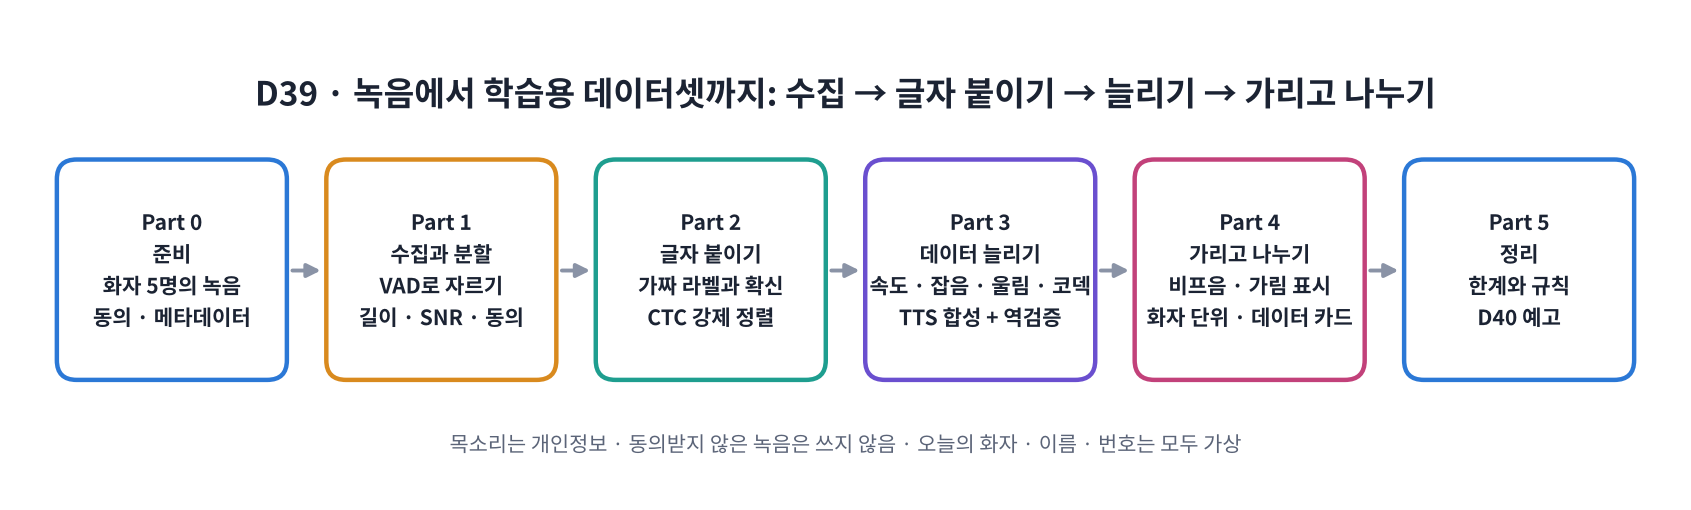

| 교시 | 내용 | 실습 | 산출물 |
|---|---|---|---|
| 1교시 | 수집: 동의 · 메타데이터, VAD 분할, 품질 지표(SNR · 길이) | Part 0 ~ 1 · ✍️ 직접 작성 1 (SNR) | 조각 표 · 품질 거르기 |
| 2교시 | 가짜 라벨과 확신, CTC 강제 정렬 | Part 2 · ✍️ 직접 작성 2 (확신) | 확신 vs 오류 표 · 낱말 시각 |
| 3교시 | 증강(속도 · 잡음 · 울림 · 코덱), TTS 합성 데이터와 역검증 | Part 3 · ✍️ 직접 작성 3 (SNR 맞춰 섞기) | 증강별 CER 표 · 합성 데이터 |
| 4교시 | 비식별화(비프 · 가림), 화자 단위 나누기, 데이터셋과 데이터 카드 | Part 4 ~ 5 · ✍️ 직접 작성 4 (비프음) · 워크시트 25문항 | **미니 데이터셋 + 데이터 카드** |

## 오늘의 수업 자료
| 자료 | 링크 | 언제 쓰나요 |
|---|---|---|
| 🎬 인터랙티브 애니메이션 | [animation.html](https://imguru-mooc.github.io/AI_Voice/day39/animation.html) | VAD 분할(D39-2) · SNR과 품질 거르기(D39-3) · 가짜 라벨과 확신(D39-4) · CTC 강제 정렬(D39-5) · 증강(D39-6) · 비식별화(D39-7) · 화자 단위 나누기(D39-8). 탭마다 **▶ 시연 보기**를 누르면 자막과 함께 스스로 움직입니다 |
| 📝 개념 워크시트 | [worksheet.html](https://imguru-mooc.github.io/AI_Voice/day39/worksheet.html) | 수업을 모두 마친 뒤 하루 한 장 25문항 (객관식 · OX · 모두 고르기 · 선 잇기 · 순서 · 코드 직접 쓰기 · 계산 · 분류 · 직접 조작), 오답 정리 → 노션 |

## 이 노트북 사용법
- ▶️ 위에서부터 차례로 실행합니다. **키가 필요 없습니다.**
- ⭐ **핵심 코드** 셀은 완성된 코드입니다. 실행한 뒤 `# ⭐` 표시가 붙은 줄을 읽어 보세요. 🔍 **핵심 줄 해설 보기**를 누르면 설명이 펼쳐집니다.
- ✍️ **직접 작성** 셀은 교시마다 하나씩, 모두 네 개입니다. `...` 자리에 코드를 직접 쓰고 실행하면 ✅ 또는 ❌가 나옵니다. 막히면 💡 **힌트 보기**, 다 쓴 뒤에는 🔑 **정답 보기**를 누르세요. 작성하지 않아도 아래 셀은 그대로 실행됩니다.
- ✏️ 표시 줄은 값을 **직접 바꿔** 다시 실행해 보는 줄입니다.

| 표시 | 뜻 |
|---|---|
| 💬 **쉽게 말하면** | 그 절의 내용을 한 문장으로 |
| 🍎 **비유** | 일상의 장면으로 바꿔 보기 |
| 👣 **한 단계씩** | 무슨 일이 어떤 순서로 일어나는지 |
| 📐 **핵심 식 하나** | 꼭 기억할 규칙 하나 |
| ❓ **생각해 보기** | 스스로 답해 보고 토론 |
| 🎧 **들어 보기** | 소리로 확인 |

> ⚙️ **런타임 → T4 GPU** 권장. 오늘 쓰는 목소리는 모두 **합성 음성**이고 화자 · 이름 · 전화번호 · 동의 기록은 **가상**입니다. 실제 녹음을 모으는 절차를 흉내 내어 연습합니다.
>
> ⚖️ **오늘의 약속**: 목소리는 **개인정보이자 생체 정보**입니다(D35). 동의받지 않은 녹음은 좋은 데이터여도 쓰지 않습니다. 오늘 만든 데이터셋과 녹음 파일은 **노션 · 공개 저장소에 올리지 않습니다.**

> 🎬 **애니메이션 D39-1:** [오늘의 흐름](https://imguru-mooc.github.io/AI_Voice/day39/animation.html#flow) — 녹음이 조각이 되고, 걸러지고, 글자가 붙고, 가려져 데이터셋이 되기까지 몇 개가 남는지

> ## 🎤 1교시 · 도입 (5분) — 슬라이드 p.1 ~ 3 · 🎬 D39-1
>
> 🎯 오늘은 모델이 아니라 **데이터**를 만든다. 녹음이 데이터셋이 되기까지 일곱 단계가 있다.
>
> 🗣️ "어제 통역기가 '스케일링'을 못 옮겼죠. D13에서 LoRA로 파인튜닝하는 법은 배웠습니다. 그런데 그때 데이터는 누가 만들었나요? 남이 만들어 둔 것을 내려받았습니다. 회사에 가면 그런 데이터가 없습니다. 통화 녹음 파일 천 개가 폴더에 있을 뿐입니다. 오늘은 그 폴더에서 `load_from_disk` 한 줄로 읽히는 데이터셋까지 갑니다."
>
> 🖥️ [D39-1](https://imguru-mooc.github.io/AI_Voice/day39/animation.html#flow)을 띄워 점들이 흘러가는 모습을 보여 줍니다. "점 하나가 녹음 조각 하나입니다. 어디서 떨어져 나가고 어디서 새로 들어오는지 보세요."
>
> ❓ "녹음 100시간이 있으면 학습 데이터 100시간이 생길까요?" → 아니다. 침묵 · 잡음 · 동의 없음 · 글자 없음으로 줄어든다.
>
> ⚠️ 오늘의 약속(노트북 맨 위의 ⚖️)을 소리 내어 읽습니다. 오늘 만든 데이터셋과 녹음은 노션 · 공개 저장소에 올리지 않습니다.

## Part 0. 준비

> 🛠️ 데이터셋 형식을 다루는 `datasets`만 확인합니다(Colab에 이미 있음). Whisper · Edge TTS는 D27 ~ D38과 같습니다.

In [ ]:
# 📦 설치: Colab 기본 패키지 버전은 그대로 고정하고 필요한 것만 추가 (런타임 재시작 불필요, 1 ~ 2분)
import importlib.metadata as md
KEEP = ["torch", "torchaudio", "torchvision", "torchcodec", "transformers", "tokenizers", "huggingface-hub", "datasets",
        "accelerate", "diffusers", "numpy", "scipy", "librosa", "numba", "safetensors", "requests",
        "click", "filelock", "rich", "typer", "pydantic", "httpx"]
pins = []
for p in KEEP:
    try:
        pins.append(f"{p}=={md.version(p)}")
    except md.PackageNotFoundError:
        pass
open("colab_constraints.txt", "w").write("\n".join(pins) + "\n")
print("고정한 버전:", ", ".join(pins))
!pip install -q -c colab_constraints.txt soundfile uroman edge-tts datasets
print("✅ 설치 완료")

In [ ]:
import os, re, io, sys, json, time, math, random, shutil, hashlib, warnings, logging, tempfile, functools
import numpy as np
import pandas as pd
import librosa
import torch
import requests
import soundfile as sf
import matplotlib.pyplot as plt
from scipy import signal
from IPython.display import Audio, display, Markdown
from datasets import Dataset, DatasetDict, load_from_disk, Audio as HFAudio   # 데이터셋 형식 (D11) · HFAudio = 소리 열의 형식
import importlib.metadata as md
warnings.filterwarnings("ignore")
logging.getLogger("transformers").setLevel(logging.ERROR)

GPU = torch.cuda.is_available()
DEVICE = "cuda" if GPU else "cpu"
SR = 16000                                               # 말소리 분석용 (Whisper · 감정 · AST)
print(" · ".join(f"{p} {md.version(p)}" for p in ["transformers", "datasets", "librosa", "torch"]))
print("GPU:", torch.cuda.get_device_name(0) if GPU else "없음 (CPU로도 가능, 조금 느림)")

def verify(cond, what=""):                               # ⭐ 핵심 코드 셀: 결과가 예상과 같은지 스스로 확인
    print(f"✅ 확인: {what}" if cond else f"⚠️ 예상과 다릅니다: {what} → 위 셀을 고쳤다면 원래대로 되돌려 다시 실행하세요.")

def practice(run, want, tol=1e-4):                       # ✍️ 직접 작성 셀 채점: 아직 안 썼거나 오류가 나도 노트북은 계속 실행됨
    try:
        got = run()
    except Exception as e:
        print(f"❌ 실행 중 오류가 났습니다 ({type(e).__name__}: {str(e)[:90]}) · 아래 💡 힌트 보기를 눌러 보세요."); return False
    items = got if isinstance(got, (list, tuple)) else [got]
    if any(x is None or x is Ellipsis for x in items):
        print("✍️ 아직 작성 전입니다. '...' 줄을 지우고 코드를 쓴 뒤 다시 실행하세요. (작성하지 않아도 아래 셀은 그대로 실행됩니다)"); return False
    try:
        ok = bool(np.allclose(np.asarray(got, float), np.asarray(want, float), atol=tol))
    except (TypeError, ValueError):
        ok = list(items) == list(want if isinstance(want, (list, tuple)) else [want])
    show = lambda v: str([round(float(x), 4) if isinstance(x, (int, float, np.floating)) else x for x in (v if isinstance(v, (list, tuple)) else [v])])[:110]
    print("✅ 정답입니다! 🎉" if ok else f"❌ 결과가 다릅니다. 내 결과 {show(got)} · 기대 {show(want)} · 아래 💡 힌트 보기를 눌러 보세요.")
    return ok

def set_seed(s=0):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)
    if GPU: torch.cuda.manual_seed_all(s)

def to_np(y):
    y = y.detach().cpu().numpy() if torch.is_tensor(y) else np.asarray(y)
    return y.reshape(-1).astype(np.float32)

def play(y, sr=SR, label=""):
    y = to_np(y)
    print(f"🎧 {label}  ({len(y) / sr:.2f}초)")
    if len(y): display(Audio(y, rate=sr))
    else: print("   (소리 없음: 위의 경고 · 오류를 확인하세요)")

def silence(sec, sr=SR):
    return np.zeros(int(sec * sr), np.float32)

def cer(ref, hyp):                                       # 글자 오류율 (D10): 공백 · 문장 부호를 빼고 편집 거리 ÷ 정답 글자 수
    r, h = [re.sub(r"[^0-9A-Za-z가-힣]", "", s) for s in (ref, hyp)]
    d = list(range(len(h) + 1))
    for i, a in enumerate(r, 1):
        prev, d[0] = d[0], i
        for j, b in enumerate(h, 1):
            prev, d[j] = d[j], min(d[j] + 1, d[j - 1] + 1, prev + (a != b))
    return d[-1] / max(1, len(r))

In [ ]:
# 🔊 모델 준비 (D27 ~ D38과 같음): 받아쓰기 Whisper · 합성 Edge TTS (예비 MMS-TTS)
from transformers import AutoTokenizer, VitsModel, WhisperProcessor, WhisperForConditionalGeneration
import uroman as ur
tts_tok = AutoTokenizer.from_pretrained("facebook/mms-tts-kor")
tts_model = VitsModel.from_pretrained("facebook/mms-tts-kor").to(DEVICE).eval()
U = ur.Uroman()
ASR_NAME = "openai/whisper-small" if GPU else "openai/whisper-tiny"
asr_proc = WhisperProcessor.from_pretrained(ASR_NAME)
asr = WhisperForConditionalGeneration.from_pretrained(ASR_NAME).to(DEVICE).eval()

import functools, tempfile
VOICE_BOT, VOICE_USER = "ko-KR-SunHiNeural", "ko-KR-InJoonNeural"   # ✏️ Edge 신경망 음성: 비서 · 사용자 대역
TTS_ENGINE = "edge"                                      # 인터넷 · 서비스 문제로 실패하면 자동으로 "mms"(예비)

@functools.lru_cache(maxsize=512)                        # 같은 문장은 다시 요청하지 않음
def _edge_tts(text, voice):
    import edge_tts
    fd, path = tempfile.mkstemp(suffix=".mp3"); os.close(fd)
    try:
        edge_tts.Communicate(text, voice).save_sync(path)
        return librosa.load(path, sr=SR)[0].astype(np.float32)   # MP3 24 kHz → 16 kHz
    finally:
        os.remove(path)

def _mms_tts(text, seed=0):                              # 예비: MMS-TTS 한국어 VITS (D16)
    set_seed(seed)
    enc = tts_tok(U.romanize_string(text), return_tensors="pt").to(DEVICE)
    with torch.no_grad():
        return to_np(tts_model(**enc).waveform[0])

def tts(text, seed=0, voice=None):                       # 글자 → 16 kHz 소리: Edge 신경망 음성, 실패하면 MMS-TTS
    global TTS_ENGINE
    if TTS_ENGINE == "edge":
        try:
            return _edge_tts(text, voice or VOICE_BOT).copy()
        except Exception as e:
            print(f"⚠️ Edge TTS 실패 → MMS-TTS로 전환 ({type(e).__name__}: {str(e)[:80]})"); TTS_ENGINE = "mms"
    return _mms_tts(text, seed)

def user_tts(text, seed=0):                              # 사용자 대역 목소리: 비서와 다른 목소리 (MMS 예비일 때는 3반음 낮춰 구분)
    y = tts(text, seed=seed, voice=VOICE_USER)
    return librosa.effects.pitch_shift(y, sr=SR, n_steps=-3) if TTS_ENGINE == "mms" else y

def stt(y):                                              # 16 kHz 소리 → 글자
    feats = asr_proc.feature_extractor(to_np(y), sampling_rate=SR, return_tensors="pt").input_features.to(DEVICE)
    with torch.no_grad():
        ids = asr.generate(input_features=feats, language="korean", task="transcribe", max_new_tokens=96)
    return asr_proc.batch_decode(ids, skip_special_tokens=True)[0].strip()

def make_voice(text):                                    # 앞 0.5초 · 뒤 1초 조용함을 붙인 '사용자 말'
    y = np.concatenate([silence(0.5), user_tts(text), silence(1.0)]).astype(np.float32)
    return y / (np.abs(y).max() + 1e-9) * 0.8

print("받아쓰기 확인:", stt(tts("한빛치과입니다. 무엇을 도와드릴까요?")))

> ## 🎤 Part 0 (설치 · 모델 준비)
>
> ✅ "받아쓰기 확인: 한빛치과입니다. 무엇을 도와드릴까요?"가 나오면 준비 끝입니다.
>
> ⚠️ `⚠️ Edge TTS 실패 → MMS-TTS로 전환`이 나오면 오늘 화자 다섯 명이 **한 목소리의 높낮이 변조**가 됩니다. 수업은 진행되지만 "화자가 다르다"는 느낌이 약합니다. 그 반은 강사 화면의 소리를 함께 듣습니다.
>
> 💡 imports에서 `Audio as HFAudio`로 불러온 까닭을 묻는 학생이 있습니다. 소리 재생에 쓰는 IPython의 `Audio`와 이름이 겹치기 때문입니다.

## Part 1. 수집과 분할: 동의, 메타데이터, 조각 내기  ·  1교시

어제 통역기가 '스케일링'이나 우리 병원의 말투를 잘 옮기지 못했다면, 고치는 방법은 모델이 아니라 **데이터**입니다. D12 · D13에서 파인튜닝을 해 봤지만 그때는 남이 만들어 둔 데이터셋을 썼습니다. 오늘은 **녹음 파일에서 학습용 데이터셋까지** 직접 만듭니다.

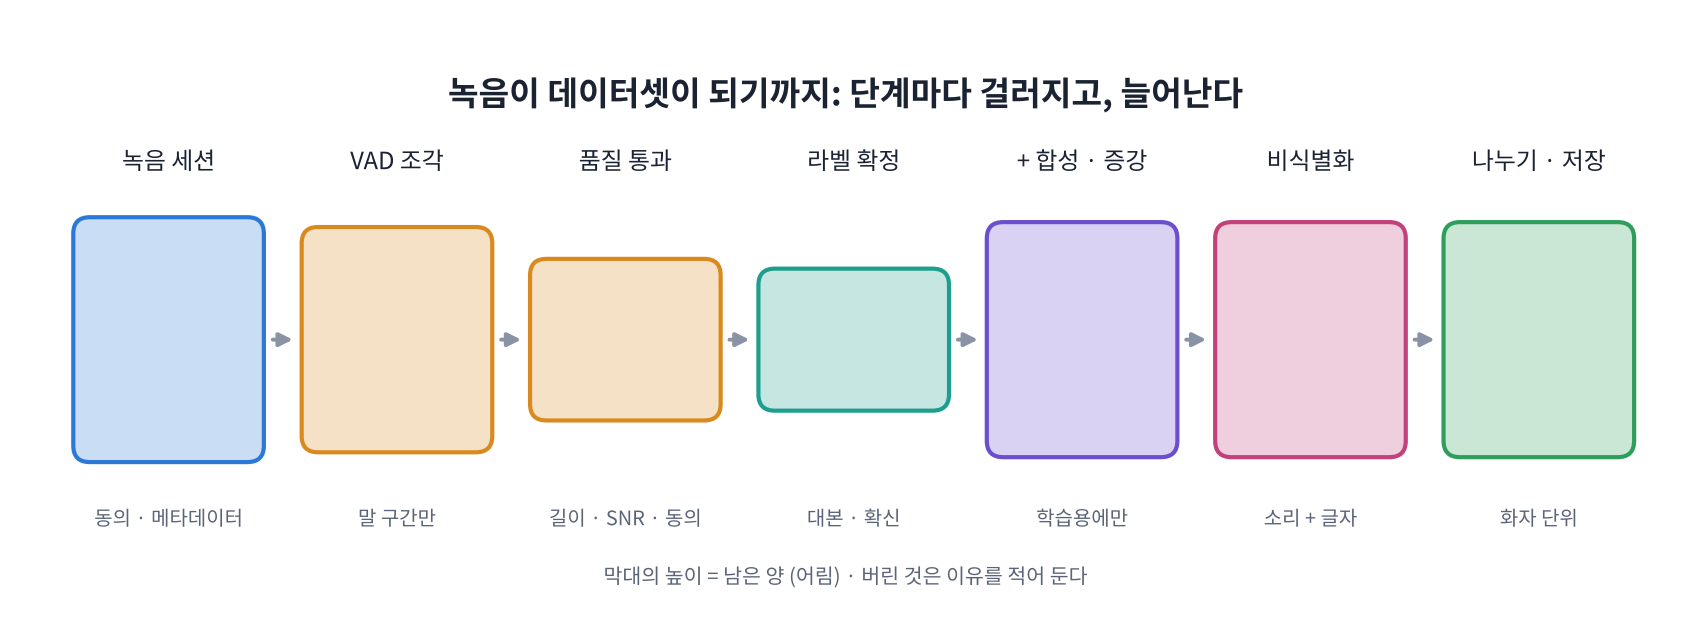

### 1-1. 녹음을 모으기 전에 정하는 것

| 정할 것 | 내용 | 오늘 코드 |
|---|---|---|
| **동의** | 누가, 무엇에(학습 · 평가 · 공개), 언제까지 쓰도록 허락했는지. **철회하면 지울 수 있어야 함** | `CONSENT` |
| **녹음 가이드** | 조용한 곳, 마이크와의 거리, 표본화율(16 kHz 이상), 읽을 대본 또는 자유 발화 | 대본 `SCRIPT` |
| **메타데이터** | 화자(가명) · 성별 · 나이대 · 기기 · 장소 · 날짜. 나중에 **치우침**을 확인하고 **화자 단위로 나누는** 데 씀 | `SESSIONS` |

> 💬 **쉽게 말하면**: 녹음 파일만 있고 "누가, 무슨 허락으로, 어떤 조건에서 녹음했는지"가 없으면 그 데이터는 쓸 수 없는 데이터입니다.

> 🍎 **비유**: 식당의 식재료와 같습니다. 재료가 아무리 좋아도 **어디서 왔는지(원산지), 언제 들어왔는지(유통기한), 써도 되는지(검수)** 가 적혀 있지 않으면 주방에 들이지 않습니다.

> ## 🎤 Part 1-1 · 동의와 메타데이터 (5분) — 슬라이드 p.4
>
> 🎯 녹음 파일만으로는 데이터가 아니다. **누가 · 무슨 허락으로 · 어떤 조건에서**가 함께 있어야 한다.
>
> 🗣️ "데이터 엔지니어링의 첫 단계는 코드가 아니라 서류입니다. 동의서에 무엇을 적어야 할까요? 학습에 써도 되는지, 공개해도 되는지, 언제까지인지, 그리고 **마음이 바뀌면 어떻게 빼 달라고 하는지**."
>
> 🍎 식재료 비유를 읽습니다. 원산지 · 유통기한 · 검수.
>
> ❓ "메타데이터에 화자의 실명을 적으면 안 되는 까닭은?" → 데이터셋이 퍼지면 실명도 함께 퍼진다. 가명(S01)으로 적고, 가명과 실명을 잇는 표는 따로 접근을 제한해 둔다.

In [ ]:
# 📥 가상의 수집: 화자 5명의 녹음 세션 + 동의 기록 (모두 합성 음성 · 가상의 인물)
SCRIPT = ["안녕하세요, 스케일링 예약을 하고 싶습니다.", "다음 주 수요일 오후 두 시에 가능한가요?", "제 이름은 김민준입니다.",
          "전화번호는 공일공 일이삼사 오육칠팔입니다.", "사랑니가 아파서 진료를 받고 싶어요.", "임플란트 상담은 얼마나 걸리나요?",
          "건강보험이 적용되는지 궁금합니다.", "주차장은 건물 지하에 있나요?", "예약 시간을 금요일로 바꿀 수 있을까요?", "감사합니다, 그때 뵙겠습니다."]
NAMES = {"S01": "김민준", "S02": "이서연", "S03": "박지호", "S04": "최유나", "S05": "정하윤"}       # 가상의 이름 (3번째 문장에서 자기 이름을 말함)
SPEAKERS = [dict(id="S01", voice="ko-KR-InJoonNeural", rate=0, pitch=0, noise_db=-55, device="headset", place="quiet room"),
            dict(id="S02", voice="ko-KR-SunHiNeural", rate=0, pitch=0, noise_db=-45, device="phone", place="office"),
            dict(id="S03", voice="ko-KR-InJoonNeural", rate=12, pitch=25, noise_db=-33, device="phone", place="cafe"),          # 시끄러운 곳
            dict(id="S04", voice="ko-KR-SunHiNeural", rate=-8, pitch=-20, noise_db=-50, device="laptop", place="quiet room"),
            dict(id="S05", voice="ko-KR-InJoonNeural", rate=-6, pitch=-15, noise_db=-48, device="phone", place="home")]
CONSENT = {"S01": dict(train=True, publish=False, until="2028-12-31"), "S02": dict(train=True, publish=False, until="2028-12-31"),
           "S03": dict(train=True, publish=False, until="2027-06-30"), "S04": dict(train=False, publish=False, until=None),      # S04는 동의를 철회함
           "S05": dict(train=True, publish=False, until="2027-06-30")}

@functools.lru_cache(maxsize=512)
def _say(text, voice, rate, pitch):
    import edge_tts
    fd, path = tempfile.mkstemp(suffix=".mp3"); os.close(fd)
    try:
        edge_tts.Communicate(text, voice, rate=f"{rate:+d}%", pitch=f"{pitch:+d}Hz").save_sync(path)
        return librosa.load(path, sr=SR)[0].astype(np.float32)
    finally:
        os.remove(path)

def say(text, voice=VOICE_BOT, rate=0, pitch=0):         # 글자 → 16 kHz 소리 (목소리 · 빠르기 · 높이를 바꿔 여러 화자 흉내)
    global TTS_ENGINE
    if TTS_ENGINE == "edge":
        try:
            return _say(text, voice, rate, pitch).copy()
        except Exception as e:
            print(f"⚠️ Edge TTS 실패 → MMS-TTS로 전환 ({type(e).__name__}: {str(e)[:80]})"); TTS_ENGINE = "mms"
    y = tts(text)
    return librosa.effects.pitch_shift(y, sr=SR, n_steps=pitch / 8) if pitch else y

SESSIONS = []
for k, sp in enumerate(SPEAKERS):
    rng = np.random.default_rng(k); parts, truth, t = [silence(0.8)], [], 0.8
    for line in SCRIPT:
        text = line.replace("김민준", NAMES[sp["id"]]); y = say(text, sp["voice"], sp["rate"], sp["pitch"]); gap = float(rng.uniform(0.7, 1.4))
        truth.append((round(t, 2), round(t + len(y) / SR, 2), text)); parts += [y, silence(gap)]; t += len(y) / SR + gap
    wav = np.concatenate(parts); wav = wav + rng.standard_normal(len(wav)).astype(np.float32) * 10 ** (sp["noise_db"] / 20)   # 방의 잡음
    SESSIONS.append(dict(speaker=sp["id"], wav=wav, truth=truth, device=sp["device"], place=sp["place"], date="2026-11-17"))
display(pd.DataFrame([{"화자": s["speaker"], "길이(초)": round(len(s["wav"]) / SR, 1), "기기": s["device"], "장소": s["place"],
                       "학습 동의": CONSENT[s["speaker"]]["train"], "공개 동의": CONSENT[s["speaker"]]["publish"], "기한": CONSENT[s["speaker"]]["until"]} for s in SESSIONS]))
play(SESSIONS[0]["wav"][:12 * SR], SR, "S01 세션의 앞 12초"); play(SESSIONS[2]["wav"][:12 * SR], SR, "S03 세션의 앞 12초 (시끄러운 곳)")

> ## 🎤 세션 녹음 만들기 (5분)
>
> 🗣️ "실제 녹음 대신 TTS로 화자 다섯 명을 흉내 냅니다. 한 사람이 문장 열 개를 이어 읽은 **긴 녹음 하나**가 세션입니다. 문장 사이의 쉼은 0.7 ~ 1.4초로 제각각이고, 화자마다 방의 잡음이 다릅니다."
>
> 🎧 S01과 S03의 앞 12초를 같이 듣습니다. "뒤에 깔린 소리가 다르죠. S03은 카페입니다."
>
> ✅ 표에서 확인시킬 것: **S04의 학습 동의가 False.** "이 사람의 녹음은 깨끗합니다. 그래도 끝까지 한 조각도 안 들어갑니다. 4교시에 확인합니다."
>
> 💡 `truth`에는 문장마다의 시작 · 끝 시각과 글자가 들어 있습니다. 우리가 만든 녹음이라 정답을 아는 것이고, 뒤에서 VAD · 가짜 라벨의 품질을 재는 데 씁니다. 실제 녹음에는 이런 것이 없습니다.

🎧 **들어 보기**: 두 녹음을 비교해 보세요. S03은 뒤에 잡음이 깔려 있습니다. 표에서 **S04의 '학습 동의'가 False**인 것도 확인하세요. 이 화자의 녹음은 품질이 좋아도 데이터셋에 **넣지 않습니다.**

### 1-2. 긴 녹음을 문장 조각으로: VAD 분할

모델은 30초 안팎의 조각으로 학습합니다(Whisper는 30초). 몇 분짜리 세션 녹음을 **말이 있는 구간**만 골라 자릅니다. D4의 VAD, D31의 끝점 검출과 같은 일입니다.

👣 **한 단계씩**
1. 20 ms마다 소리의 크기(dB)를 잼
2. 그 녹음의 **조용한 수준(바닥)** 보다 일정 dB 이상 큰 조각을 '말'로 표시
3. 말 사이의 짧은 틈(0.3초 미만)은 이어 붙이고, 앞뒤에 0.1초의 여유를 둠
4. 너무 짧은 구간(0.3초 미만)은 버림

> 🎬 **애니메이션 D39-2:** [VAD 분할](https://imguru-mooc.github.io/AI_Voice/day39/animation.html#vad) — 문턱과 '틈 메우기'를 바꾸면 조각이 어떻게 합쳐지고 쪼개지는지

> ## 🎤 Part 1-2 · VAD 분할 (10분) — 슬라이드 p.5 · 🎬 D39-2
>
> 🎯 문턱은 고정된 값이 아니라 **그 녹음의 바닥보다 몇 dB**. 틈 메우기가 문장을 쪼개거나 붙인다.
>
> 🖥️ [D39-2](https://imguru-mooc.github.io/AI_Voice/day39/animation.html#vad) → ▶ 시연 보기. 틈을 0.1로 줄이면 둘째 문장이 쪼개지고, 0.6으로 늘리면 셋째 · 넷째가 붙는 것, 카페로 바꿔도 문턱이 따라 올라가는 것을 보여 줍니다.
>
> 🗣️ "D4에서 VAD, D31에서 끝점 검출을 했습니다. 같은 일입니다. 다른 점은 실시간이 아니라서 **녹음 전체를 보고** 바닥을 잴 수 있다는 것입니다."

In [ ]:
# ⭐ 핵심 코드: 긴 녹음을 말 구간으로 자르기 (에너지 VAD)
VAD_UP, VAD_GAP, VAD_PAD, VAD_MIN = 8.0, 0.3, 0.1, 0.3   # ✏️ 바닥보다 몇 dB 크면 말인가 · 메울 틈(초) · 앞뒤 여유(초) · 가장 짧은 조각(초)
HOP = 320                                                # 20 ms

def frame_db(y):
    rms = librosa.feature.rms(y=to_np(y), frame_length=2 * HOP, hop_length=HOP)[0]
    return 20 * np.log10(rms + 1e-9)

def vad_split(y):                                        # → [(시작 초, 끝 초), ...]
    db = frame_db(y); floor = np.percentile(db, 10)                                # ⭐ 이 녹음의 조용한 수준 (아래에서 10% 지점)
    speech = db > floor + VAD_UP                                                   # ⭐ 바닥보다 VAD_UP dB 넘게 큰 조각 = 말
    segs, start = [], None
    for i, on in enumerate(np.r_[speech, False]):
        if on and start is None: start = i
        if not on and start is not None:
            s, e = start * HOP / SR, i * HOP / SR; start = None
            if segs and s - segs[-1][1] < VAD_GAP: segs[-1] = (segs[-1][0], e)     # ⭐ 짧은 틈은 앞 구간에 이어 붙임
            else: segs.append((s, e))
    return [(max(0.0, s - VAD_PAD), min(len(y) / SR, e + VAD_PAD)) for s, e in segs if e - s >= VAD_MIN]

rows = []
for ses in SESSIONS:
    for k, (s, e) in enumerate(vad_split(ses["wav"])):
        rows.append(dict(id=f'{ses["speaker"]}_{k:02d}', speaker=ses["speaker"], start=round(s, 2), end=round(e, 2), wav=ses["wav"][int(s * SR):int(e * SR)]))
SEGS = pd.DataFrame(rows)
fig, ax = plt.subplots(figsize=(12, 2.2)); y = SESSIONS[2]["wav"]; ax.plot(np.arange(len(y)) / SR, y, lw=0.4, color="#7B8496")
for s, e in vad_split(y): ax.axvspan(s, e, color="#1E9E8F", alpha=0.25)
ax.set_xlabel("time (s) · shaded = speech segments found by VAD"); ax.set_title("S03 session (noisy)", fontsize=10); plt.tight_layout(); plt.show()
print("화자별 조각 수:", SEGS.groupby("speaker").size().to_dict(), "· 대본은 화자마다", len(SCRIPT), "문장")
verify(SEGS[SEGS.speaker == "S01"].shape[0] == len(SCRIPT) and all(SEGS.end > SEGS.start), "조용한 S01 세션은 대본의 문장 수만큼 잘렸고, 모든 조각의 끝이 시작보다 뒤")

> ## 🎤 ⭐ vad_split 읽기
>
> 🔍 `# ⭐` 세 줄을 읽습니다.
> - `floor = np.percentile(db, 10)` — "크기를 작은 순서로 늘어놓고 10% 지점. 녹음에서 가장 조용한 편의 수준입니다."
> - `speech = db > floor + VAD_UP` — "거기서 8 dB 넘게 크면 말."
> - `if segs and s - segs[-1][1] < VAD_GAP` — "앞 구간이 끝나고 0.3초도 안 돼 다시 시작하면 같은 구간으로 이어 붙입니다."
>
> ✅ 그림에서 S03(시끄러운 세션)의 말 구간이 초록으로 칠해집니다. 아래 줄의 "화자별 조각 수"가 모두 10이면 문장대로 잘린 것입니다.
>
> ⚠️ 실제 Edge 음성은 문장 안에 쉼표 쉼이 있어("안녕하세요, 스케일링 …") 어떤 화자는 11 ~ 12개로 쪼개질 수 있습니다. **그것이 정상이고 좋은 토론거리입니다.** "쪼개진 조각은 어떻게 되나?" → 2교시에 대본과 맞지 않아 걸러지거나, 반쪽 문장으로 남는다. `VAD_GAP`을 0.4로 올려 다시 실행해 보입니다.
>
> 🧪 `VAD_UP = 20`으로 바꿔 실행 → 조각이 부서지거나 사라집니다. 되돌려 놓습니다.

<details>
<summary><b>🔍 핵심 줄 해설 보기 (클릭)</b></summary>

```python
db = frame_db(y); floor = np.percentile(db, 10)
speech = db > floor + VAD_UP
if segs and s - segs[-1][1] < VAD_GAP: segs[-1] = (segs[-1][0], e)
```

**해설**: 문턱을 "−38 dB"처럼 **고정된 값**이 아니라 **그 녹음의 바닥보다 몇 dB**로 잡은 것이 핵심입니다(D36의 '기준선'과 같은 생각). 시끄러운 S03과 조용한 S01은 바닥이 20 dB 넘게 다르기 때문에, 고정 문턱 하나로는 둘 다 맞출 수 없습니다. `VAD_GAP`은 "사랑니가 … 아파서"처럼 말 중간의 짧은 틈에서 문장이 둘로 쪼개지지 않게 합니다. 너무 크게 잡으면 반대로 두 문장이 하나로 붙습니다. 화자별 조각 수를 보세요. 대본은 10문장인데 조각 수가 다르다면 그 세션에서 **쪼개지거나 붙은** 것입니다. 이런 차이는 뒤 단계에서 '글자와 소리가 안 맞는 조각'이 되어 걸러집니다. 실제 프로젝트에서는 D4의 Silero VAD 같은 학습된 VAD를 쓰지만, 값을 정하는 원리(문턱 · 틈 · 여유 · 최소 길이)는 같습니다.

</details>

In [ ]:
# ✍️ 직접 작성 1 (1교시): 신호 대 잡음비 SNR(dB)
# speech는 말이 있는 구간의 표본들, noise는 말이 없는 구간의 표본들입니다(둘 다 numpy 배열).
# 10 × log10(말의 평균 제곱 ÷ 잡음의 평균 제곱)을 돌려주세요. (1 ~ 2줄)
def snr_db(speech, noise):
    ...                                                  # ← 이 줄을 지우고 작성하세요

_one = np.ones(100)
W1_OK = practice(lambda: [snr_db(_one, 0.1 * _one), snr_db(2 * _one, _one), snr_db(_one, _one), snr_db(0.5 * _one, _one), snr_db(np.array([3.0, -3.0]), np.array([0.3, -0.3]))],
                 [20.0, 6.0206, 0.0, -6.0206, 20.0], tol=1e-3)

<details>
<summary><b>💡 힌트 보기 (클릭)</b></summary>

1. 평균 제곱(세기)은 `np.mean(x ** 2)`입니다. 말과 잡음에 각각 구합니다.
2. 두 세기의 비율에 `np.log10`을 씌우고 10을 곱합니다.
3. 한 줄로: `return 10 * np.log10(np.mean(speech ** 2) / np.mean(noise ** 2))`.

</details>

<details>
<summary><b>🔑 정답 보기 (클릭)</b></summary>

```python
def snr_db(speech, noise):
    return 10 * np.log10(np.mean(speech ** 2) / np.mean(noise ** 2))
```

**해설**: SNR은 "말이 잡음보다 **몇 배 센가**"를 dB로 적은 것입니다. 진폭이 10배면 세기(제곱)는 100배이고 `10 × log10(100) = 20 dB`입니다. 진폭이 2배면 약 6 dB, 같으면 0 dB, 잡음이 더 크면 음수입니다. 흔한 실수는 제곱을 빼먹고 `np.mean(speech) / np.mean(noise)`로 쓰는 것입니다. 소리는 0을 중심으로 위아래로 흔들리므로 그냥 평균은 0에 가깝고, 다섯 번째 시험(`[3, -3]`)에서 0으로 나누게 됩니다. `20 * np.log10(...)`은 **진폭(RMS)의 비율**에 쓰는 식이고, 세기의 비율에는 10을 곱합니다. 둘은 같은 값입니다. 여기서 '말이 있는 구간'에는 사실 잡음도 섞여 있어서 엄밀히는 (말 + 잡음) ÷ 잡음이지만, SNR이 10 dB를 넘으면 차이가 작아 이렇게 어림합니다.

</details>

> ## 🎤 ✍️ 직접 작성 1 · SNR (7분) — 슬라이드 p.6 · 🎬 D39-3
>
> 🎯 SNR = 10 × log10(말의 **평균 제곱** ÷ 잡음의 **평균 제곱**).
>
> 🆘 단계별 힌트 (학생용 💡와 같은 순서)
> 1. 세기는 `np.mean(x ** 2)`
> 2. 두 세기의 비율에 `np.log10`, 곱하기 10
> 3. `return 10 * np.log10(np.mean(speech ** 2) / np.mean(noise ** 2))`
>
> ⚠️ 가장 흔한 오답: 제곱을 빼먹음 → 다섯 번째 시험에서 0으로 나누거나 값이 절반(10 dB)으로 나옵니다. 둘째: `20 *`을 곱함 → 값이 두 배. "20은 진폭의 비율에, 10은 세기의 비율에."
>
> 🖥️ [D39-3](https://imguru-mooc.github.io/AI_Voice/day39/animation.html#snr)에서 잡음을 키우며 "10 dB마다 세기 10배"를 눈으로 확인합니다.

In [ ]:
# 🧪 조각마다 품질 재기 → 거르기: 길이 · SNR · 동의
MIN_SEC, MAX_SEC, MIN_SNR = 1.0, 15.0, 15.0              # ✏️ 조각 길이의 범위(초) · 가장 낮은 SNR(dB)

def quality(seg, session_wav):                           # 조각의 SNR: 조각 안의 큰 부분(말)과 세션에서 가장 조용한 부분(잡음)을 비교
    db = frame_db(session_wav); quiet = db < np.percentile(db, 10) + 3
    noise = np.concatenate([session_wav[i * HOP:(i + 1) * HOP] for i in np.where(quiet)[0][:200]])
    sdb = frame_db(seg); loud = np.concatenate([seg[i * HOP:(i + 1) * HOP] for i in np.where(sdb > np.percentile(sdb, 50))[0]])
    return 10 * np.log10(np.mean(loud ** 2) / np.mean(noise ** 2))

WAV_OF = {s["speaker"]: s["wav"] for s in SESSIONS}
SEGS["sec"] = (SEGS.end - SEGS.start).round(2)
SEGS["snr"] = [round(float(quality(r.wav, WAV_OF[r.speaker])), 1) for r in SEGS.itertuples()]
SEGS["consent"] = SEGS.speaker.map(lambda s: CONSENT[s]["train"])
SEGS["why"] = [("동의 없음" if not r.consent else "길이" if not MIN_SEC <= r.sec <= MAX_SEC else "SNR 낮음" if r.snr < MIN_SNR else "") for r in SEGS.itertuples()]
SEGS["ok"] = SEGS.why == ""
display(SEGS.groupby("speaker").agg(조각=("id", "size"), 평균_길이=("sec", "mean"), 평균_SNR=("snr", "mean"), 통과=("ok", "sum")).round(1))
print("버린 이유:", SEGS[~SEGS.ok].why.value_counts().to_dict(), f"· 전체 {len(SEGS)}개 가운데 {int(SEGS.ok.sum())}개 통과")
if globals().get("W1_OK"):
    print("내가 만든 snr_db로 확인:", {s["speaker"]: round(float(snr_db(s["wav"][int(s["truth"][0][0] * SR):int(s["truth"][0][1] * SR)], s["wav"][:int(0.6 * SR)])), 1) for s in SESSIONS})

> ## 🎤 품질 거르기 · 토론 (8분)
>
> ✅ 표에서 볼 것: S03의 평균 SNR이 가장 낮고 통과가 0이거나 적다. S04는 SNR이 높아도 통과 0(동의 없음). "버린 이유" 줄에 `SNR 낮음`과 `동의 없음`이 나옵니다.
>
> 🗣️ "버릴 때는 **이유를 적어 둡니다.** 나중에 '왜 30%나 버렸느냐'는 질문에 답해야 하고, 기준을 바꾸면 무엇이 되살아나는지 알아야 합니다."
>
> ❓ 생각해 보기 1번을 꼭 다룹니다. "S03을 다 버리는 게 맞나요?" → 학습용으로는 뺄 수 있지만, 우리 손님이 카페에서 전화한다면 **평가용**에는 그런 녹음이 있어야 한다. 깨끗한 것만 남기면 깨끗한 것만 잘하는 모델이 된다. 기준은 쓰임새가 정한다.
>
> ❓ 2번: 철회하면? → 조각과 파일을 지우고, 그 데이터로 학습한 모델이 무엇인지도 기록해 둔다(4교시 `remove_speaker`).
>
> ➡️ "조각은 생겼습니다. 그런데 글자가 없습니다."

**❓ 생각해 보기**
1. S03(카페)의 조각을 **모두 버리는 것**이 옳을까요? 우리 서비스의 실제 통화가 시끄러운 곳에서 온다면 어떤 데이터가 필요한가요? (학습용과 **평가용**의 기준은 달라야 할까요?)
2. S04의 녹음은 품질이 좋습니다. 그래도 넣지 않는 까닭을 '동의' 표의 칸으로 설명해 보세요. 동의를 **나중에 철회**하면 이미 만든 데이터셋은 어떻게 해야 할까요?
3. 메타데이터의 '기기 · 장소'가 한쪽으로 쏠려 있으면(예: 모두 조용한 방의 헤드셋) 학습한 모델에 어떤 일이 생길까요?

> 🎬 **애니메이션 D39-3:** [SNR과 품질 거르기](https://imguru-mooc.github.io/AI_Voice/day39/animation.html#snr) — 잡음을 키우며 SNR이 문턱 아래로 내려가는 지점 찾기

> ⏸️ **1교시 끝.** 워크시트는 4교시가 끝난 뒤 한 번에 풉니다.

## Part 2. 글자 붙이기: 가짜 라벨과 강제 정렬  ·  2교시

조각만 있고 글자가 없으면 학습에 쓸 수 없습니다. 글자를 붙이는 길은 두 가지입니다.

| 상황 | 방법 | 얻는 것 |
|---|---|---|
| **대본이 없음** (자유 발화, 통화 녹음) | 큰 모델이 받아쓴 글을 정답처럼 씀 = **가짜 라벨** (pseudo-label) | 글자 + **확신**(얼마나 믿을 만한가) |
| **대본이 있음** (녹음 가이드대로 읽음) | 대본의 글자를 소리에 맞춰 놓기 = **강제 정렬** (forced alignment) | 글자마다 · 낱말마다의 **시각** |

### 2-1. 가짜 라벨: 큰 모델에게 받아쓰게 하고, 확신으로 거르기

사람이 모든 녹음을 받아쓰는 것은 비쌉니다(1시간 녹음에 4 ~ 8시간). 그래서 큰 모델의 받아쓰기를 정답 대신 씁니다. 문제는 그 받아쓰기가 **틀릴 수 있다**는 것입니다. 틀린 글자로 학습하면 모델은 틀린 것을 배웁니다. 그래서 모델이 **스스로 얼마나 확신했는지**를 보고 낮은 것을 버립니다.

📐 **핵심 식 하나**: `확신 = exp(토큰 로그 확률의 평균)`. 토큰마다의 확률을 곱해 토큰 수로 제곱근을 낸 것(기하 평균)과 같습니다. 1에 가까울수록 모든 토큰을 자신 있게 고른 것입니다.

> 💬 **쉽게 말하면**: 조교가 채점한 답안 가운데 조교 스스로 "이건 자신 있다"고 한 것만 성적에 넣습니다.

> 🍎 **비유**: 받아쓰기 시험을 잘 보는 선배에게 필기를 빌립니다. 선배도 가끔 틀리므로, 선배가 **물음표를 쳐 둔 곳**은 베끼지 않습니다.

> 🎬 **애니메이션 D39-4:** [가짜 라벨과 확신](https://imguru-mooc.github.io/AI_Voice/day39/animation.html#pseudo) — 확신 문턱을 올리면 남는 데이터의 양과 틀린 라벨의 비율이 어떻게 맞바뀌는지

> ## 🎤 2교시 · Part 2-1 가짜 라벨 (6분) — 슬라이드 p.7 · 🎬 D39-4
>
> 🎯 큰 모델의 받아쓰기를 정답처럼 쓰되, **모델 스스로의 확신**으로 거른다.
>
> 🗣️ "한 시간 녹음을 사람이 받아쓰면 네 시간에서 여덟 시간이 걸립니다. 천 시간이면? 그래서 Whisper에게 시킵니다. 문제는 Whisper도 틀린다는 것. 틀린 글자로 학습하면 틀린 것을 배웁니다."
>
> 🍎 선배의 필기 비유. "선배가 물음표 친 곳은 안 베낍니다."
>
> 🖥️ [D39-4](https://imguru-mooc.github.io/AI_Voice/day39/animation.html#pseudo) → ▶ 시연 보기. 문턱을 올리며 빨간 점이 빠지는 것, **오른쪽 끝의 빨간 점(이름 · 전화번호 · 용어)** 은 안 빠지는 것을 짚습니다.

In [ ]:
# ⭐ 핵심 코드: 가짜 라벨 붙이기 — 받아쓴 글 + 확신 (토큰 로그 확률)
def pseudo_label(y):                                     # → (받아쓴 글, 확신 0 ~ 1)
    feats = asr_proc.feature_extractor(to_np(y), sampling_rate=SR, return_tensors="pt").input_features.to(DEVICE)
    with torch.no_grad():
        out = asr.generate(input_features=feats, language="korean", task="transcribe", max_new_tokens=96,
                           output_scores=True, return_dict_in_generate=True)                               # ⭐ 토큰마다의 점수도 함께 받음
    lp = asr.compute_transition_scores(out.sequences, out.scores, normalize_logits=True)[0]                # ⭐ 고른 토큰들의 로그 확률
    lp = lp[torch.isfinite(lp)]
    conf = float(torch.exp(lp.mean())) if len(lp) else 0.0                                                 # ⭐ 평균 로그 확률 → 확신
    return asr_proc.batch_decode(out.sequences, skip_special_tokens=True)[0].strip(), conf

TRUTH = {}                                                # 조각 id → 대본 문장: 조각과 시간이 가장 많이 겹치는 문장 (절반 넘게 겹칠 때만)
for r in SEGS.itertuples():
    ov, text = max((min(r.end, e) - max(r.start, s), t) for s, e, t in next(x for x in SESSIONS if x["speaker"] == r.speaker)["truth"])
    if ov > 0.5 * (r.end - r.start): TRUTH[r.id] = text
labels = [pseudo_label(r.wav) for r in SEGS.itertuples()]
SEGS["text"], SEGS["conf"] = [t for t, _ in labels], [round(c, 3) for _, c in labels]
SEGS["cer"] = [round(cer(TRUTH[r.id], r.text), 3) if r.id in TRUTH else np.nan for r in SEGS.itertuples()]
with pd.option_context("display.max_colwidth", 44):
    display(SEGS.sort_values("conf").head(5)[["id", "sec", "snr", "conf", "cer", "text"]])
rows = []
for th in [0.0, 0.5, 0.7, 0.8, 0.9]:
    keep = SEGS[SEGS.conf >= th]
    rows.append({"확신 문턱": th, "남는 조각": len(keep), "남는 비율": f"{len(keep) / len(SEGS):.0%}", "남은 것의 평균 CER": round(float(keep.cer.mean()), 3) if len(keep) else None,
                 "틀린 라벨(CER > 10%) 비율": f"{(keep.cer > 0.1).mean():.0%}" if len(keep) else "-"})
display(pd.DataFrame(rows))
verify(SEGS.conf.between(0, 1).all() and SEGS.text.map(len).gt(0).mean() > 0.8, "확신은 0 ~ 1 사이이고, 대부분의 조각에 글자가 붙음")

> ## 🎤 ⭐ pseudo_label 읽기 (11분) — 슬라이드 p.8 ~ 9
>
> 🔍
> - `output_scores=True, return_dict_in_generate=True` — "글자만 말고 토큰을 고를 때마다의 점수도 달라."
> - `compute_transition_scores(...)` — "그 가운데 실제로 고른 토큰의 로그 확률."
> - `torch.exp(lp.mean())` — "평균 내고 exp. D7의 `avg_logprob`와 같은 값입니다."
>
> ✅ 위 표: 확신이 낮은 조각 5개. 시끄러운 S03의 조각이나 이름 · 전화번호 문장이 올라오는 경향입니다. 아래 표: 문턱을 올릴수록 '남는 조각'이 줄고 '평균 CER'이 내려가는 경향.
>
> ⚠️ 표가 깔끔하게 나오지 않을 수 있습니다(조각이 50개뿐이고 합성 음성이라 대부분 잘 받아씁니다). 모든 줄의 CER이 비슷하면 "우리 데이터는 깨끗해서 차이가 작다. 실제 통화 녹음에서는 차이가 크다"고 설명하고 애니메이션으로 보충합니다.
>
> ❓ "확신이 0.95인데 CER이 높은 조각이 있나요?" 있으면 같이 봅니다. 이름이나 숫자일 가능성이 큽니다. "모델은 자신 있게 틀립니다."
>
> 💡 `TRUTH`는 조각마다 시간이 가장 많이 겹치는 대본 문장을 짝지은 것입니다. 실제로는 정답이 없으므로 표본 100개쯤을 사람이 받아써서 문턱을 정합니다.

<details>
<summary><b>🔍 핵심 줄 해설 보기 (클릭)</b></summary>

```python
out = asr.generate(..., output_scores=True, return_dict_in_generate=True)
lp = asr.compute_transition_scores(out.sequences, out.scores, normalize_logits=True)[0]
conf = float(torch.exp(lp.mean()))
```

**해설**: `generate`에 `output_scores=True`를 주면 글자뿐 아니라 **토큰을 고를 때마다의 점수**를 돌려줍니다. `compute_transition_scores`는 그 가운데 **실제로 고른 토큰**의 로그 확률만 뽑습니다. 그 평균에 `exp`를 씌운 것이 확신입니다. D7에서 Whisper의 환각을 거를 때 쓴 `avg_logprob`와 같은 값입니다. 위 표(확신이 낮은 조각 5개)를 보세요. 확신이 낮은 조각의 CER이 높은 편인가요? 대체로 그렇지만 **항상은 아닙니다.** 모델은 자신 있게 틀리기도 합니다(이름 · 숫자 · 전문 용어에서 특히). 아래 표는 문턱을 올릴 때 **남는 양과 라벨의 깨끗함이 맞바뀌는** 모습입니다. D36 · D37에서 본 문턱의 맞바꿈과 같은 구조입니다. 실무에서는 문턱 하나로 끝내지 않고 ① 높은 확신은 그대로 쓰고 ② 중간은 사람이 확인하고 ③ 낮은 것은 버리는 세 갈래로 나눕니다. 여기서 CER을 잴 수 있는 것은 우리가 대본을 알기 때문입니다(조각마다 시간이 가장 많이 겹치는 대본 문장을 `TRUTH`에 짝지었습니다). 진짜 가짜 라벨 상황에서는 정답이 없으므로, 일부 표본만 사람이 받아써서 문턱을 정합니다.

</details>

In [ ]:
# ✍️ 직접 작성 2 (2교시): 토큰 로그 확률들에서 '확신'을 구하는 함수
# logprobs는 토큰마다의 로그 확률이 든 리스트(또는 numpy 배열)입니다. 평균을 낸 뒤 exp를 씌워 돌려주세요.
# 리스트가 비어 있으면 0.0을 돌려줍니다. (1 ~ 2줄)
def confidence(logprobs):
    ...                                                  # ← 이 줄을 지우고 작성하세요

if practice(lambda: [confidence([0.0, 0.0, 0.0]), confidence([-0.1, -0.3]), confidence([-1.0]), confidence(np.log([0.9, 0.9, 0.1])), confidence([])],
            [1.0, 0.81873, 0.36788, 0.43267, 0.0], tol=1e-4):
    print("토큰 확률이 [0.9, 0.9, 0.9]일 때:", round(confidence(np.log([0.9, 0.9, 0.9])), 3), " · [0.99, 0.99, 0.3]일 때:", round(confidence(np.log([0.99, 0.99, 0.3])), 3))

<details>
<summary><b>💡 힌트 보기 (클릭)</b></summary>

1. 빈 리스트면 평균을 낼 수 없습니다: `if len(logprobs) == 0: return 0.0`.
2. 평균은 `np.mean(logprobs)`, 지수 함수는 `np.exp(...)` 또는 `math.exp(...)`입니다.
3. `return float(np.exp(np.mean(logprobs)))`.

</details>

<details>
<summary><b>🔑 정답 보기 (클릭)</b></summary>

```python
def confidence(logprobs):
    if len(logprobs) == 0:
        return 0.0
    return float(np.exp(np.mean(logprobs)))
```

**해설**: 로그 확률의 **평균**에 exp를 씌우면 확률들의 **기하 평균**이 됩니다. 토큰 확률이 `[0.9, 0.9, 0.1]`이면 `(0.9 × 0.9 × 0.1)^(1/3) = 0.433`입니다. 그냥 평균(산술 평균)은 0.63으로 더 높게 나오는데, 기하 평균을 쓰는 까닭은 **한 토큰만 크게 틀려도** 값이 뚝 떨어지게 하기 위해서입니다. 받아쓰기에서 토큰 하나가 틀리면 그 문장은 틀린 라벨이기 때문입니다. 합(`np.sum`)을 쓰면 문장이 길수록 값이 작아져 **긴 문장이 불리**해집니다. 그래서 길이로 나눈 평균을 씁니다. 실행 결과의 두 번째 예(`[0.99, 0.99, 0.3]`)를 보세요. 대부분 자신 있어도 한 곳이 불확실하면 확신은 0.67로 내려갑니다.

</details>

> ## 🎤 ✍️ 직접 작성 2 · 확신 (7분)
>
> 🎯 확신 = exp(로그 확률의 **평균**) = 토큰 확률의 기하 평균.
>
> 🆘
> 1. 빈 리스트면 `return 0.0`
> 2. `np.mean(logprobs)`에 `np.exp`
> 3. `return float(np.exp(np.mean(logprobs)))`
>
> ⚠️ 흔한 오답: `np.sum`을 씀 → 긴 문장일수록 값이 작아짐(네 번째 시험에서 0.081). 빈 리스트 처리를 빼먹음 → `nan`.
>
> 🗣️ 정답 뒤 출력을 읽습니다. "[0.99, 0.99, 0.3]이면 0.665. 세 토큰 가운데 하나만 불확실해도 뚝 떨어집니다. 그래서 산술 평균(0.76)이 아니라 기하 평균을 씁니다."

### 2-2. 강제 정렬: 대본의 글자가 소리의 어디에 있는가

대본이 있으면 글자를 새로 받아쓸 필요가 없습니다. 대신 **"이 글자는 몇 초부터 몇 초까지인가"** 를 찾습니다. 이것이 있어야 ① 긴 녹음을 대본의 문장대로 자르고 ② 4교시에 **이름이 나오는 구간만** 비프음으로 가릴 수 있습니다.

D6에서 배운 **CTC 모델**은 20 ms 프레임마다 "이 프레임은 어떤 글자(또는 빈칸)인가"의 확률을 냅니다. 강제 정렬은 그 확률표 위에서 **대본의 글자를 순서대로 지나가는 길 가운데 확률이 가장 큰 길**을 찾는 것입니다.

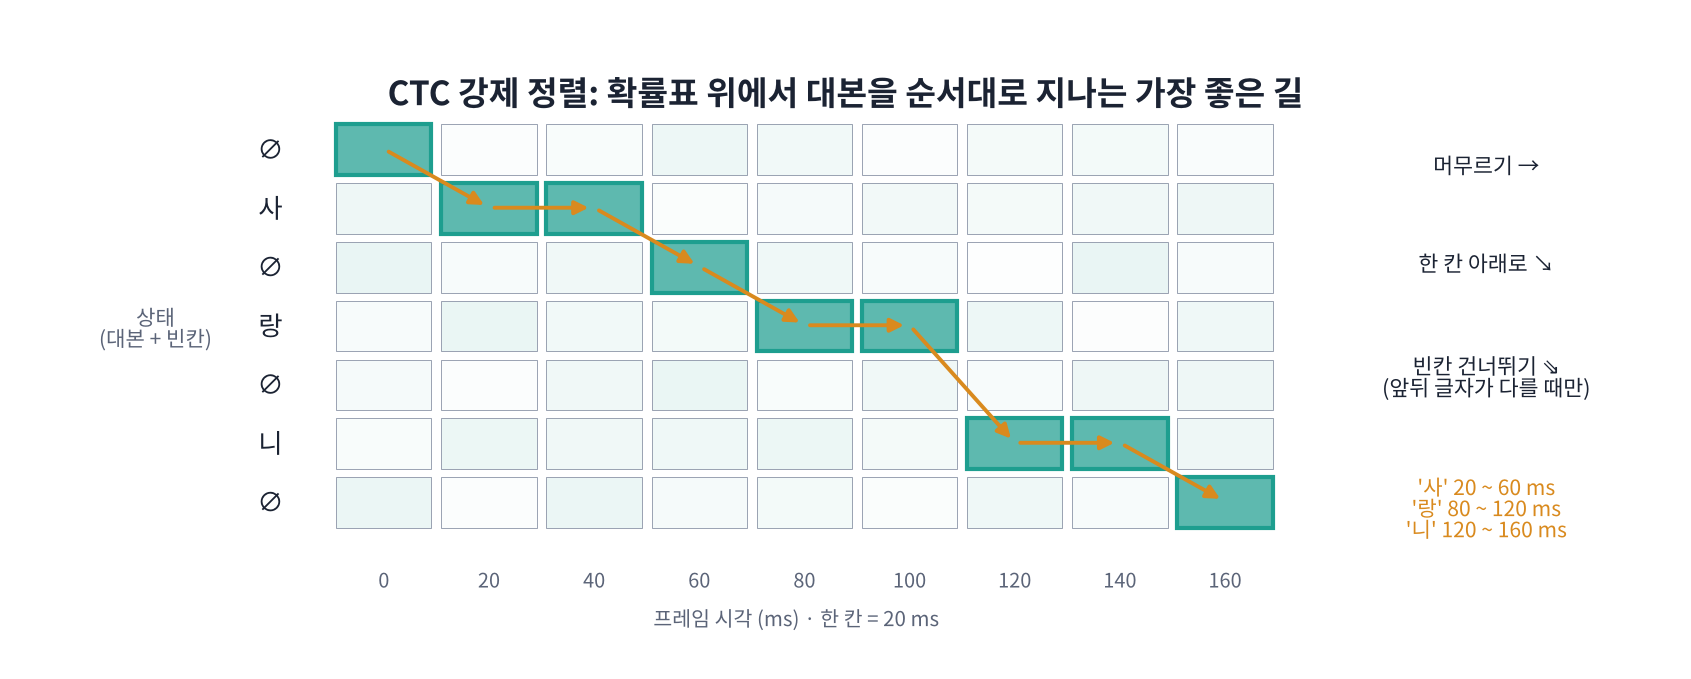

👣 **한 단계씩** (대본 `사랑니`, 프레임 8개)
1. 대본의 글자 사이사이에 빈칸(∅)을 끼워 상태를 만듦: `∅ 사 ∅ 랑 ∅ 니 ∅`
2. 프레임마다 **머무르기 · 다음 상태로 · (글자가 다르면) 빈칸을 건너뛰기** 가운데 지금까지의 점수가 가장 큰 쪽을 고름
3. 마지막 프레임에서 거꾸로 따라가면 프레임마다 어느 글자였는지가 정해짐
4. 글자가 차지한 첫 프레임 ~ 마지막 프레임 × 20 ms = 글자의 시각

> 💬 **쉽게 말하면**: 노래방 가사가 박자에 맞춰 색이 바뀌게 만드는 일입니다. 가사(대본)는 이미 있고, **언제** 불렀는지만 찾습니다.

> 🎬 **애니메이션 D39-5:** [CTC 강제 정렬](https://imguru-mooc.github.io/AI_Voice/day39/animation.html#align) — 확률표 위에서 가장 좋은 길이 한 칸씩 그려지는 모습

> ## 🎤 Part 2-2 · 강제 정렬 개념 (9분) — 슬라이드 p.10 · 🎬 D39-5
>
> 🎯 강제 정렬은 **글자는 이미 알고, 언제인지만** 찾는다. 확률표 위의 가장 좋은 길.
>
> 🗣️ "노래방 가사를 생각하세요. 가사는 이미 있습니다. 박자에 맞춰 색이 바뀌게 하려면 글자마다 시각이 필요합니다. 오늘은 그 시각으로 4교시에 **이름이 나오는 구간만** 가릴 겁니다."
>
> 🖥️ [D39-5](https://imguru-mooc.github.io/AI_Voice/day39/animation.html#align) → ▶ 시연 보기. 프레임을 하나씩 늘리며 "길은 머무르거나 아래로만 간다, 위로는 못 간다"를 보여 줍니다. '하하'로 바꿔 빈칸을 꼭 지나는 것도 봅니다.
>
> ❓ "D6에서 CTC가 '사사∅랑'을 '사랑'으로 줄였죠. 그 규칙을 거꾸로 쓰면?" → 같은 글자가 이어지면 한 글자로 합쳐지므로, 두 글자로 세려면 사이에 빈칸이 있어야 한다.

In [ ]:
# ⭐ 핵심 코드: CTC 강제 정렬 — 프레임마다의 글자 확률표에서 대본을 따라가는 가장 좋은 길 (모델 약 1.2 GB)
CTC_NAME = "kresnik/wav2vec2-large-xlsr-korean"          # ✏️ 한국어 글자 단위 CTC 모델 (D6)
CTC_OK = False
try:
    from transformers import Wav2Vec2ForCTC, Wav2Vec2Processor
    ctc_proc = Wav2Vec2Processor.from_pretrained(CTC_NAME); ctc = Wav2Vec2ForCTC.from_pretrained(CTC_NAME).to(DEVICE).eval(); CTC_OK = True
except Exception as e:
    print(f"⚠️ CTC 모델을 올리지 못했습니다 ({type(e).__name__}: {str(e)[:100]}) → 정렬은 글자 수에 비례해 어림합니다.")

def ctc_align(emission, tokens, blank):                  # emission: (프레임 수, 글자 종류 수) 로그 확률 · tokens: 대본의 글자 번호들
    T, S = emission.shape[0], 2 * len(tokens) + 1
    sym = [blank if s % 2 == 0 else tokens[s // 2] for s in range(S)]              # 상태: ∅ 글자 ∅ 글자 ∅ …
    dp = np.full((T, S), -np.inf); back = np.zeros((T, S), int)
    dp[0, 0], dp[0, 1] = emission[0, sym[0]], emission[0, sym[1]]
    for t in range(1, T):
        for s in range(S):
            cands = [dp[t - 1, s], dp[t - 1, s - 1] if s >= 1 else -np.inf,
                     dp[t - 1, s - 2] if s >= 2 and s % 2 == 1 and sym[s] != sym[s - 2] else -np.inf]    # ⭐ 머무르기 · 한 칸 · (다른 글자면) 빈칸 건너뛰기
            k = int(np.argmax(cands)); dp[t, s] = cands[k] + emission[t, sym[s]]; back[t, s] = s - k     # ⭐ 가장 점수가 큰 길 + 이 프레임의 점수
    s = S - 1 if dp[-1, S - 1] >= dp[-1, S - 2] else S - 2; path = []
    for t in range(T - 1, -1, -1):                                                 # ⭐ 끝에서 거꾸로 따라가기
        path.append(s); s = back[t, s]
    path = path[::-1]
    return [(min(t for t, p in enumerate(path) if p == 2 * i + 1), max(t for t, p in enumerate(path) if p == 2 * i + 1)) for i in range(len(tokens))]

def align_words(y, text):                                # → [(낱말, 시작 초, 끝 초), ...]
    words = text.split(); chars = [c for c in re.sub(r"[^가-힣 ]", "", text).replace(" ", "")]
    if CTC_OK and chars:
        with torch.no_grad():
            em = torch.log_softmax(ctc(ctc_proc(to_np(y), sampling_rate=SR, return_tensors="pt").input_values.to(DEVICE)).logits[0], dim=-1).cpu().numpy()
        ids = ctc_proc.tokenizer.convert_tokens_to_ids(chars); unk = ctc_proc.tokenizer.unk_token_id
        if unk not in ids and len(em) >= 2 * len(ids):
            spans = ctc_align(em, ids, ctc_proc.tokenizer.pad_token_id); sec = len(y) / SR / len(em)      # 프레임 하나의 길이(초), 약 20 ms
            out, k = [], 0
            for w in words:
                n = len(re.sub(r"[^가-힣]", "", w))
                if n: out.append((w, round(spans[k][0] * sec, 2), round((spans[k + n - 1][1] + 1) * sec, 2))); k += n
            return out
    db = frame_db(y); on = np.where(db > np.percentile(db, 10) + VAD_UP)[0]         # 예비: 말 구간을 글자 수에 비례해 나눔 (정확하지 않음)
    s0, s1 = (on[0] * HOP / SR, (on[-1] + 1) * HOP / SR) if len(on) else (0.0, len(y) / SR)
    n_all = max(1, len(chars)); out, k = [], 0
    for w in words:
        n = len(re.sub(r"[^가-힣]", "", w)); out.append((w, round(s0 + (s1 - s0) * k / n_all, 2), round(s0 + (s1 - s0) * (k + n) / n_all, 2))); k += n
    return out

em = np.log(np.array([[.6, .3, .1], [.1, .8, .1], [.1, .7, .2], [.6, .2, .2], [.1, .1, .8], [.2, .1, .7]]))   # 장난감 확률표: 0 = ∅, 1 = '가', 2 = '나'
print("장난감 예 (대본 '가나', 프레임 6개) → 글자마다의 (첫 프레임, 마지막 프레임):", ctc_align(em, [1, 2], 0))
r = next((x for x in SEGS.itertuples() if "전화번호" in TRUTH.get(x.id, "")), SEGS.iloc[3]); text = TRUTH.get(r.id, r.text)
WORDS = align_words(r.wav, text); print("낱말 시각:", WORDS)
fig, ax = plt.subplots(figsize=(12, 2)); ax.plot(np.arange(len(r.wav)) / SR, r.wav, lw=0.4, color="#7B8496")
for k, (w, s, e) in enumerate(WORDS): ax.axvspan(s, e, color=["#1E9E8F", "#D98A1E"][k % 2], alpha=0.25); ax.text((s + e) / 2, ax.get_ylim()[1] * 0.8, f"w{k + 1}", ha="center", fontsize=9)
ax.set_xlabel("time (s) · shaded = aligned words (w1, w2, ...)"); plt.tight_layout(); plt.show()
verify(ctc_align(em, [1, 2], 0) == [(1, 2), (4, 5)] and all(e > s for _, s, e in WORDS) and all(a[2] <= b[1] + 0.03 for a, b in zip(WORDS, WORDS[1:])),
       "장난감 예에서 '가'는 프레임 1 ~ 2, '나'는 4 ~ 5 · 실제 조각의 낱말들은 시간 순서대로 겹치지 않게 놓임")

> ## 🎤 ⭐ ctc_align 읽기 (12분) — 슬라이드 p.11
>
> 🔍 장난감 예(프레임 6개, 대본 '가나')를 칠판에 6 × 5 표로 그리고 손으로 따라갑니다.
> - `cands = [머무르기, 한 칸, 건너뛰기]` — "한 프레임 전에 올 수 있는 곳은 세 군데뿐."
> - `dp[t, s] = cands[k] + emission[t, sym[s]]` — "가장 좋은 데서 와서 이 칸의 점수를 더함."
> - `path.append(s); s = back[t, s]` — "끝에서 거꾸로."
>
> ✅ 장난감 예: `[(1, 2), (4, 5)]`. 실제 조각: 전화번호 문장의 낱말 네 개가 시간 순서대로 나오고 그림에 번갈아 칠해집니다.
>
> ⚠️ `⚠️ CTC 모델을 올리지 못했습니다`가 나온 학생은 낱말 시각이 글자 수에 비례한 어림값입니다. 그림은 비슷해 보이지만 정확하지 않다고 알려 주세요.
>
> 💡 이중 반복문이라 긴 문장에서는 느립니다(프레임 수 × 상태 수). 오늘 조각은 몇 초라 괜찮습니다. 실무 도구는 같은 계산을 벡터화하거나 C++로 합니다.
>
> ➡️ "글자와 시각이 생겼습니다. 다음 시간에는 데이터를 늘립니다."

<details>
<summary><b>🔍 핵심 줄 해설 보기 (클릭)</b></summary>

```python
cands = [dp[t - 1, s], dp[t - 1, s - 1], dp[t - 1, s - 2] if … sym[s] != sym[s - 2] …]
k = int(np.argmax(cands)); dp[t, s] = cands[k] + emission[t, sym[s]]
path.append(s); s = back[t, s]
```

**해설**: `dp[t, s]`는 "프레임 t까지 와서 상태 s에 있을 때의 가장 좋은 점수"입니다. 한 프레임 전에 올 수 있는 곳은 세 군데뿐입니다. **같은 상태에 머무르기**(글자를 길게 끌거나 빈칸이 이어짐), **바로 앞 상태에서 한 칸 오기**, 그리고 앞뒤 글자가 **서로 다를 때만** 사이의 빈칸을 **건너뛰기**입니다. 같은 글자가 연달아 나오면(예: '하하') 빈칸을 꼭 지나야 두 글자로 구분됩니다. D6에서 CTC가 반복 글자를 합치는 규칙의 반대 방향입니다. `back`에 "어디서 왔는지"를 적어 두었다가 마지막 프레임에서 거꾸로 따라가면 길이 나옵니다. 장난감 예를 손으로 따라가 보세요. 프레임 0은 ∅, 1 ~ 2는 '가', 3은 ∅, 4 ~ 5는 '나'입니다. 받아쓰기(D6의 CTC 디코딩)와 다른 점은 **무슨 글자인지는 이미 정해져 있다**는 것입니다. 그래서 받아쓰기가 틀리는 잡음 속에서도 정렬은 꽤 잘 버팁니다. 다만 **대본과 소리가 다르면**(말을 빼먹거나 더 말함) 억지로 맞춰 엉뚱한 시각을 냅니다. 그래서 정렬 점수가 낮은 조각은 버립니다. 이 셀이 `⚠️ CTC 모델을 올리지 못했습니다`를 냈다면 낱말 시각은 글자 수에 비례한 어림값입니다.

</details>

**❓ 생각해 보기**: 가짜 라벨의 받아쓰기(`SEGS.text`)와 대본(`TRUTH`)이 다른 조각을 찾아보세요. 이름(김민준 · 이서연 …)과 전화번호 문장은 어떻게 받아써졌나요? **이름 · 숫자 · 전문 용어**가 가짜 라벨에서 특히 잘 틀리는 까닭은 무엇일까요? 그런 낱말이 중요한 우리 병원 데이터에서는 어떤 조각을 **사람이 확인**해야 할까요?

> ⏸️ **2교시 끝.** 🎬 D39-4의 확신 문턱과 D39-5의 **▶ 시연 보기**를 돌려 보세요.

## Part 3. 데이터 늘리기: 증강과 합성  ·  3교시

깨끗한 녹음 30개로 학습한 모델은 깨끗한 녹음만 잘 알아듣습니다. 실제 전화는 빠르게 말하고, 시끄럽고, 울리고, 전화 코덱을 거칩니다. **증강**(augmentation)은 가진 녹음을 일부러 망가뜨려 그런 조건을 흉내 내는 것입니다.

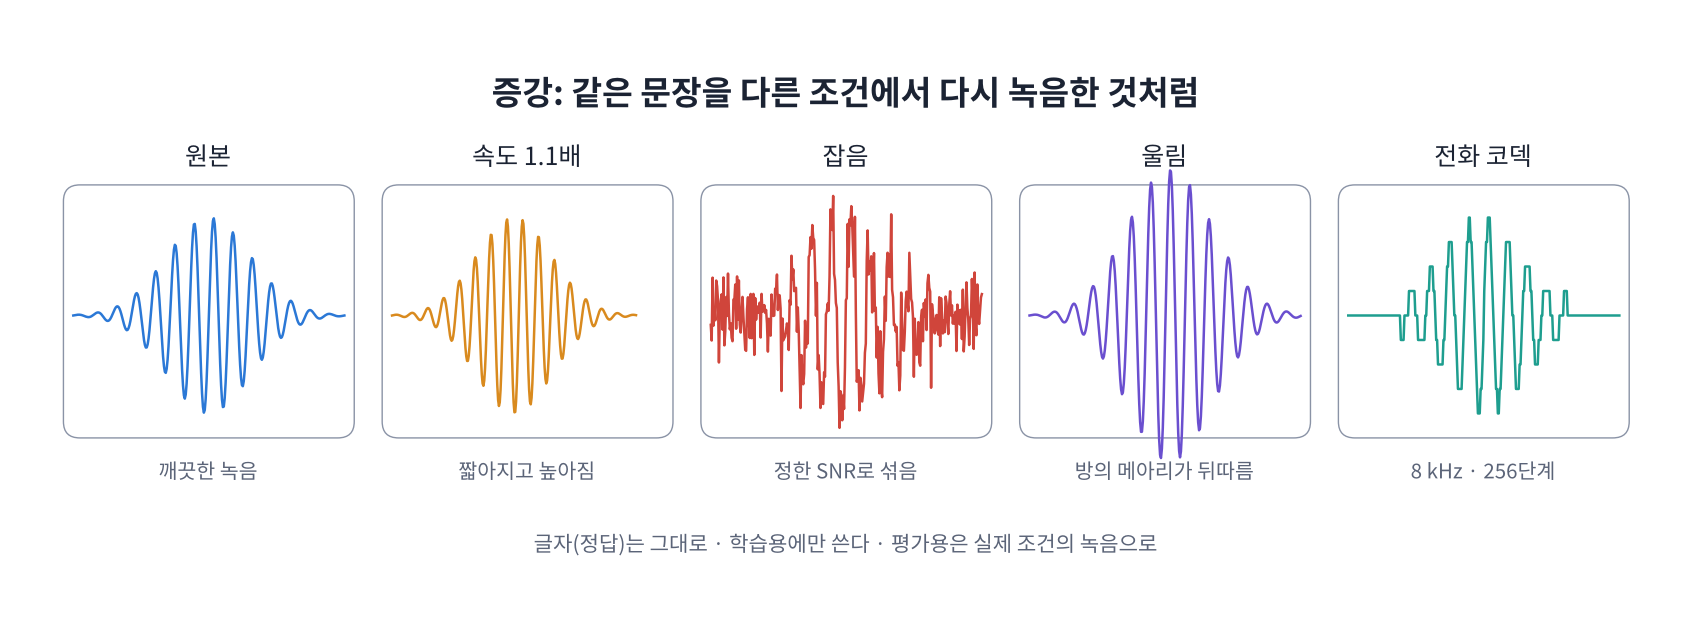

| 증강 | 흉내 내는 것 | 방법 | 어디서 배웠나 |
|---|---|---|---|
| **속도** | 빨리 · 천천히 말하는 사람 | 0.9배 · 1.1배로 다시 표본화 (높낮이도 함께 바뀜) | D2 |
| **잡음** | 카페 · 길거리 · 차 안 | 잡음을 **정한 SNR**이 되게 섞음 | D4 · D33 |
| **울림(RIR)** | 빈 방 · 복도 · 스피커폰 | 방의 울림(임펄스 응답)과 합성곱 | D33 |
| **코덱** | 전화 음질 | 8 kHz로 낮춰 μ-law로 줄였다가 되돌림 | D30 |

📐 **핵심 식 하나**: 잡음을 SNR `d` dB로 섞으려면 `잡음에 곱할 값 = √(말의 세기 ÷ (잡음의 세기 × 10^(d/10)))`

> 💬 **쉽게 말하면**: 같은 문장을 '빠르게', '시끄러운 곳에서', '울리는 방에서', '전화로' 다시 녹음한 것처럼 만듭니다. 글자(정답)는 그대로입니다.

> ⚠️ 증강은 **학습용에만** 씁니다. 평가용 데이터는 실제 조건의 녹음이어야 합니다. 증강한 소리로 평가하면 "우리가 만든 잡음에 강한지"만 알게 됩니다.

> 🎬 **애니메이션 D39-6:** [증강](https://imguru-mooc.github.io/AI_Voice/day39/animation.html#augment) — 네 가지 증강이 파형과 받아쓰기 오류에 주는 영향

> ## 🎤 3교시 · Part 3 증강 (6분) — 슬라이드 p.12 · 🎬 D39-6
>
> 🎯 증강은 가진 녹음을 **일부러 망가뜨려** 실제 조건을 흉내 내는 것. 글자는 그대로, **학습용에만**.
>
> 🗣️ "깨끗한 녹음 서른 개로 학습한 모델은 깨끗한 녹음만 잘합니다. 실제 전화는 빠르고, 시끄럽고, 울리고, 전화망을 거칩니다. 네 가지 모두 앞에서 배운 것입니다. D2 표본화, D4 · D33 잡음, D33 울림, D30 μ-law."
>
> 🖥️ [D39-6](https://imguru-mooc.github.io/AI_Voice/day39/animation.html#augment)에서 하나씩 켜 보입니다.

In [ ]:
# ⭐ 핵심 코드: 네 가지 증강 — 속도 · 잡음 · 울림 · 전화 코덱
def aug_speed(y, rate=1.1):                              # 1.1배 빠르게: 표본화율을 속여 다시 표본화 (길이 ÷ rate, 높낮이 × rate)
    return librosa.resample(to_np(y), orig_sr=int(SR * rate), target_sr=SR)       # ⭐ 'SR × rate로 녹음된 소리'라고 보고 SR로 되돌림

def aug_noise(y, snr=10.0, seed=0):                      # 잡음을 SNR snr dB가 되게 섞기
    n = np.random.default_rng(seed).standard_normal(len(y)).astype(np.float32); n = np.convolve(n, np.ones(8) / 8, mode="same")   # 낮은 소리가 많은 잡음
    g = np.sqrt(np.mean(y ** 2) / (np.mean(n ** 2) * 10 ** (snr / 10)))            # ⭐ 잡음에 곱할 값
    return (y + g * n).astype(np.float32)

def aug_rir(y, rt60=0.5, seed=0):                        # 울림: 지수로 줄어드는 잡음을 방의 임펄스 응답으로 삼아 합성곱
    t = np.arange(int(rt60 * SR)) / SR; h = np.random.default_rng(seed).standard_normal(len(t)) * np.exp(-6.9 * t / rt60); h[0] = 1.0
    out = np.convolve(y, h / np.abs(h).sum() * 4)[:len(y)]                         # ⭐ 소리 * 방의 울림
    return (out / (np.abs(out).max() + 1e-9) * np.abs(y).max()).astype(np.float32)

def aug_codec(y, mu=255):                                # 전화 코덱: 8 kHz · μ-law 8비트 (D30)
    x = librosa.resample(to_np(y), orig_sr=SR, target_sr=8000); x = np.clip(x / (np.abs(x).max() + 1e-9), -1, 1)
    q = np.round((np.sign(x) * np.log1p(mu * np.abs(x)) / np.log1p(mu) + 1) / 2 * mu)                      # ⭐ 작은 소리는 촘촘하게, 큰 소리는 성기게 256단계로
    x = 2 * q / mu - 1; x = np.sign(x) * ((1 + mu) ** np.abs(x) - 1) / mu
    return (librosa.resample(x.astype(np.float32), orig_sr=8000, target_sr=SR) * np.abs(y).max()).astype(np.float32)

AUG = {"원본": lambda y: y, "속도 1.1배": aug_speed, "잡음 SNR 10 dB": aug_noise, "울림 0.5초": aug_rir, "전화 코덱": aug_codec}   # ✏️ 값을 바꿔 보세요
good = SEGS[SEGS.ok].head(8); base = good.iloc[0]
for name, f in AUG.items(): play(f(base.wav), SR, f"{name}: {TRUTH.get(base.id, base.text)}")
rows = []
for name, f in AUG.items():
    errs = [cer(TRUTH.get(r.id, r.text), stt(f(r.wav))) for r in good.itertuples()]
    rows.append({"증강": name, "길이 비율": round(len(f(base.wav)) / len(base.wav), 2), "받아쓰기 CER (조각 8개 평균)": f"{np.mean(errs):.1%}"})
display(pd.DataFrame(rows))
y = base.wav; yn = aug_noise(y, 10.0)
verify(abs(len(aug_speed(y, 1.1)) / len(y) - 1 / 1.1) < 0.01 and abs(10 * np.log10(np.mean(y ** 2) / np.mean((yn - y) ** 2)) - 10) < 0.5 and len(aug_codec(y)) == len(y),
       "1.1배 빠르게 하면 길이가 1/1.1배 · 섞은 잡음의 SNR이 10 dB · 코덱을 거쳐도 길이는 그대로")

> ## 🎤 ⭐ 네 가지 증강 (12분) — 슬라이드 p.13
>
> 🎧 다섯 소리(원본 · 속도 · 잡음 · 울림 · 코덱)를 차례로 같이 듣습니다. "어느 것이 실제 전화와 가장 비슷한가요?"
>
> 🔍
> - `librosa.resample(y, orig_sr=int(SR * rate), target_sr=SR)` — "17.6 kHz로 녹음한 것이라고 속이고 16 kHz로 되돌림. 테이프를 빨리 돌리는 것."
> - `g = np.sqrt(...)` — "잡음에 곱할 값. 다음 ✍️에서 직접 씁니다."
> - μ-law 줄 — "작은 소리는 촘촘하게, 큰 소리는 성기게. D30."
>
> ✅ 표: 길이 비율은 속도만 0.91, 나머지는 1.00. CER은 원본이 가장 낮고 잡음 · 울림 쪽이 오르는 경향입니다(실행마다 다름).
>
> ❓ "CER이 가장 많이 오른 증강은? 그것이 뜻하는 바는?" → 지금 모델이 가장 약한 조건 = 가장 필요한 데이터.
>
> ⚠️ 오개념: "증강을 많이 할수록 좋다." 사람도 못 알아듣는 SNR 0 dB는 해롭습니다. 보통 5 ~ 20 dB에서 무작위로 뽑습니다.

<details>
<summary><b>🔍 핵심 줄 해설 보기 (클릭)</b></summary>

```python
return librosa.resample(to_np(y), orig_sr=int(SR * rate), target_sr=SR)
g = np.sqrt(np.mean(y ** 2) / (np.mean(n ** 2) * 10 ** (snr / 10)))
q = np.round((np.sign(x) * np.log1p(mu * np.abs(x)) / np.log1p(mu) + 1) / 2 * mu)
```

**해설**: **속도**: 16 kHz로 녹음한 소리를 "17.6 kHz로 녹음한 것"이라고 속여 16 kHz로 되돌리면 표본 수가 1/1.1로 줄어 1.1배 빨라집니다. 테이프를 빨리 돌리는 것과 같아서 **높낮이도 함께 올라갑니다.** 다른 사람처럼 들리게 되어 화자를 늘리는 효과도 있습니다(Kaldi의 속도 섭동 0.9 · 1.0 · 1.1이 이 방식입니다). 높낮이를 그대로 두려면 D36의 `time_stretch`를 씁니다. **잡음**: 식의 뜻은 "말의 세기 ÷ (곱한 잡음의 세기) = 10^(SNR/10)"이 되게 잡음의 크기를 맞추는 것입니다. 1교시의 `snr_db`를 거꾸로 푼 식입니다. 실제로는 흰 잡음이 아니라 **녹음한 잡음**(카페 · 차 안, D33의 잡음 모음)을 씁니다. **울림**: 방에서 손뼉을 치면 들리는 '줄어드는 메아리'가 임펄스 응답(RIR)이고, 소리와 합성곱하면 그 방에서 말한 것처럼 됩니다. `rt60`은 울림이 60 dB 줄어드는 데 걸리는 시간입니다. **코덱**: μ-law는 작은 소리를 촘촘하게, 큰 소리를 성기게 256단계로 적습니다(D30의 전화 음질). 8 kHz로 낮추면서 4 kHz 위의 소리가 사라지는 것이 더 큰 변화입니다. 표의 CER을 보세요. 어떤 증강이 지금 모델에게 가장 어려운가요? **그 조건의 데이터가 가장 필요한 데이터**입니다. 다만 CER이 너무 높아지는 증강(사람도 못 알아듣는 수준)은 학습에 해롭습니다.

</details>

In [ ]:
# ✍️ 직접 작성 3 (3교시): 말과 잡음을 '정한 SNR'이 되게 섞는 함수
# speech와 noise는 길이가 같은 numpy 배열, snr은 원하는 SNR(dB)입니다.
# 잡음에 곱할 값 g = sqrt(말의 평균 제곱 ÷ (잡음의 평균 제곱 × 10^(snr/10)))을 구해 speech + g × noise를 돌려주세요. (2 ~ 3줄)
def mix_at_snr(speech, noise, snr):
    ...                                                  # ← 이 줄을 지우고 작성하세요

_s, _n = np.sin(np.arange(1600) * 0.3), np.random.default_rng(1).standard_normal(1600)
_snr = lambda mixed: None if mixed is None or mixed is Ellipsis else float(10 * np.log10(np.mean(_s ** 2) / np.mean((mixed - _s) ** 2)))   # 섞인 소리의 SNR을 다시 잼
if practice(lambda: [_snr(mix_at_snr(_s, _n, 20)), _snr(mix_at_snr(_s, _n, 10)), _snr(mix_at_snr(_s, _n, 0)), _snr(mix_at_snr(_s, 5 * _n, 10)), _snr(mix_at_snr(_s, _n, -5))],
            [20.0, 10.0, 0.0, 10.0, -5.0], tol=1e-3):
    for d in [20, 10, 0]:
        play(mix_at_snr(base.wav, np.random.default_rng(0).standard_normal(len(base.wav)).astype(np.float32), d), SR, f"SNR {d} dB로 섞은 소리")

<details>
<summary><b>💡 힌트 보기 (클릭)</b></summary>

1. 말과 잡음의 세기: `ps = np.mean(speech ** 2)`, `pn = np.mean(noise ** 2)`.
2. 잡음에 곱할 값: `g = np.sqrt(ps / (pn * 10 ** (snr / 10)))`.
3. `return speech + g * noise`.

</details>

<details>
<summary><b>🔑 정답 보기 (클릭)</b></summary>

```python
def mix_at_snr(speech, noise, snr):
    ps, pn = np.mean(speech ** 2), np.mean(noise ** 2)
    g = np.sqrt(ps / (pn * 10 ** (snr / 10)))
    return speech + g * noise
```

**해설**: 1교시의 `snr_db`는 "섞인 소리의 SNR이 얼마인가"를 **재는** 식이었고, 이 함수는 "SNR이 얼마가 되게 **섞는**" 식입니다. 원하는 것은 `ps ÷ (g² × pn) = 10^(snr/10)`이고, 이것을 g에 대해 풀면 위 식이 나옵니다. 네 번째 시험이 중요합니다. 잡음이 5배 커져서 들어와도(`5 * _n`) 결과의 SNR은 똑같이 10 dB여야 합니다. **잡음의 원래 크기와 상관없이** 원하는 SNR을 만들기 때문입니다. `g = 10 ** (-snr / 20)`처럼 잡음의 세기를 보지 않고 곱하면 이 시험에서 틀립니다. 제곱근을 빼먹으면 SNR이 두 배(20 → 40 dB)로 나옵니다. 세기는 진폭의 제곱이기 때문입니다. 학습 데이터를 만들 때는 SNR을 하나로 고정하지 않고 **5 ~ 20 dB 사이에서 무작위로** 뽑아 섞습니다.

</details>

> ## 🎤 ✍️ 직접 작성 3 · SNR 맞춰 섞기 (9분)
>
> 🎯 1교시의 SNR 식을 **거꾸로** 풀어 잡음에 곱할 값을 구한다.
>
> 🆘
> 1. `ps = np.mean(speech ** 2)`, `pn = np.mean(noise ** 2)`
> 2. `g = np.sqrt(ps / (pn * 10 ** (snr / 10)))`
> 3. `return speech + g * noise`
>
> 🗣️ 칠판에 한 줄: `ps ÷ (g² × pn) = 10^(snr/10)` → g에 대해 풀기.
>
> ⚠️ 흔한 오답: `10 ** (-snr / 20)`만 곱함(잡음의 원래 크기를 안 봄) → 네 번째 시험(잡음 5배)에서 틀림. 제곱근 빼먹음 → SNR이 두 배.
>
> 🎧 정답 뒤 SNR 20 · 10 · 0 dB 세 소리를 듣습니다. "0 dB를 사람이 알아듣나요?"

### 3-1. TTS 합성 데이터: 없는 문장을 만들어 채우기

우리 병원에서 중요한 낱말(임플란트 · 스케일링 · 신경 치료)이 들어간 녹음이 몇 개 없다면, **TTS로 만들어** 채울 수 있습니다. D20에서 TTS의 품질을 '합성 → 받아쓰기 → 원문과 비교'(역검증 CER)로 쟀던 것을 그대로 **거르는 장치**로 씁니다.

| 장점 | 주의할 점 |
|---|---|
| 원하는 문장 · 낱말을 원하는 만큼 만들 수 있음 | 합성 음성은 실제 사람보다 **깨끗하고 고름** → 그것만으로 학습하면 실제 목소리에 약해짐 |
| 글자(정답)가 처음부터 정확함 | TTS가 **잘못 읽은** 문장이 섞임 → 역검증으로 거름 |
| 동의 · 개인정보 문제가 적음 | 데이터 카드에 **합성임을 표시**하고, 실제 녹음과 섞는 비율을 정함 |

> 💬 **쉽게 말하면**: 문제집에 없는 유형의 문제를 직접 만들어 푸는 것입니다. 다만 만든 문제의 **답이 맞는지** 확인하고, 실제 시험 문제(실제 녹음)와 섞어서 풉니다.

> ## 🎤 Part 3-1 · TTS 합성 데이터 (3분) — 슬라이드 p.14
>
> 🎯 없는 문장은 TTS로 만들고, **합성 → 받아쓰기 → 원문과 비교**로 거른다.
>
> 🗣️ "우리 병원 녹음에 '임플란트'가 세 번밖에 안 나옵니다. 그럼 만들면 됩니다. D20에서 TTS 품질을 재던 역검증 CER을 오늘은 거르는 장치로 씁니다."
>
> ⚠️ 표의 '주의할 점'을 읽습니다. 합성 음성만으로 학습하면 합성 음성만 잘 알아듣습니다.

In [ ]:
# ⭐ 핵심 코드: 도메인 용어가 든 문장을 TTS로 합성하고 역검증(합성 → 받아쓰기)으로 거르기
TERMS = ["임플란트 시술은 두 번에 나눠 진행합니다.", "신경 치료 후에는 크라운을 씌워야 합니다.", "스케일링은 일 년에 한 번 건강보험이 적용됩니다.",
         "사랑니 발치 후에는 거즈를 두 시간 물고 계세요.", "교정 상담은 파노라마 촬영 후에 가능합니다.", "잇몸에서 피가 나면 치주 검사를 받아 보세요."]
SYN_VOICES = [("ko-KR-SunHiNeural", 0, 0), ("ko-KR-InJoonNeural", 0, 0), ("ko-KR-SunHiNeural", 10, 15)]      # ✏️ (목소리, 빠르기 %, 높이 Hz)
MAX_RT_CER = 0.1                                         # ✏️ 역검증 CER이 이보다 크면 버림

rows = []
for i, text in enumerate(TERMS):
    for j, (voice, rate, pitch) in enumerate(SYN_VOICES):
        y = say(text, voice, rate, pitch)
        back = stt(y)                                                              # ⭐ 합성한 소리를 다시 받아쓰기
        rt = cer(text, back)                                                       # ⭐ 원문과 얼마나 다른가 (역검증 CER)
        rows.append(dict(id=f"SYN_{i:02d}_{j}", speaker=f"TTS{j}", text=text, back=back, rt_cer=round(rt, 3), ok=rt <= MAX_RT_CER, wav=y, sec=round(len(y) / SR, 2)))
SYN = pd.DataFrame(rows)
with pd.option_context("display.max_colwidth", 40):
    display(SYN.sort_values("rt_cer", ascending=False).head(5)[["id", "text", "back", "rt_cer", "ok"]])
print(f"합성 {len(SYN)}개 가운데 {int(SYN.ok.sum())}개 통과 (역검증 CER ≤ {MAX_RT_CER:.0%}) · 평균 역검증 CER {SYN.rt_cer.mean():.1%}")
verify(len(SYN) == len(TERMS) * len(SYN_VOICES) and SYN.rt_cer.between(0, 5).all() and (SYN.ok == (SYN.rt_cer <= MAX_RT_CER)).all(), "문장 × 목소리 수만큼 합성했고, 역검증 CER이 문턱 이하인 것만 통과로 표시")

> ## 🎤 ⭐ 합성 + 역검증 (8분)
>
> ✅ 문장 6개 × 목소리 3개 = 18개. 역검증 CER이 높은 순서로 5개가 보입니다. '크라운' · '파노라마' · '치주' 같은 낱말에서 원문과 받아쓴 글이 달라지는 경향입니다.
>
> ❓ "CER이 높은 까닭은 TTS가 잘못 읽어서일까요, Whisper가 그 낱말을 몰라서일까요?" → 들어 봐야 안다. `play(SYN.iloc[k].wav)`로 하나를 같이 듣습니다. TTS가 바르게 읽었는데 받아쓰기가 틀렸다면 **그 문장이야말로 필요한 학습 데이터**입니다.
>
> 🗣️ "그래서 문턱에 걸린 것은 버리는 게 아니라 **사람이 들어 봅니다.** 자동으로 통과시킬 것과 사람이 볼 것을 나누는 선입니다."
>
> ➡️ "양은 늘었습니다. 마지막으로, 이 데이터에 들어 있으면 안 되는 것을 지웁니다."

<details>
<summary><b>🔍 핵심 줄 해설 보기 (클릭)</b></summary>

```python
back = stt(y)
rt = cer(text, back)
ok = rt <= MAX_RT_CER
```

**해설**: 역검증 CER이 높은 까닭은 두 가지입니다. **TTS가 잘못 읽었거나**(숫자 · 외래어 · 드문 낱말), **받아쓰기 모델이 그 낱말을 모르거나**입니다. 표의 '원문'과 '받아쓴 글'을 비교해 보세요. '크라운', '파노라마', '치주' 같은 낱말이 다르게 적혔다면 어느 쪽 문제일까요? 소리를 직접 들어 TTS가 바르게 읽었는데 받아쓰기가 틀린 것이라면, 그 문장은 버릴 것이 아니라 **오히려 꼭 필요한 학습 데이터**입니다(모델이 모르는 낱말이므로). 그래서 역검증으로 걸러진 것은 그냥 버리지 않고 **사람이 들어 보고** 정합니다. 문턱(`MAX_RT_CER`)은 '자동으로 통과시킬 것'을 정하는 값이지 '나머지는 쓰레기'라는 뜻이 아닙니다. 합성 데이터의 목소리는 몇 개뿐입니다. 3교시 앞부분의 증강(속도 · 잡음 · 울림 · 코덱)을 합성 음성에 겹쳐 쓰면 조금 더 다양해집니다. 그래도 실제 사람의 녹음을 대신할 수는 없습니다.

</details>

**❓ 생각해 보기**
1. 증강 표에서 CER이 가장 많이 오른 조건은 무엇인가요? 우리 병원의 전화 통화에 가장 가까운 증강을 **두 개 겹친다면** 어떤 조합일까요?
2. 합성 데이터만으로 학습한 모델을 **합성 데이터로 평가**하면 점수는 어떻게 나올까요? 그 점수를 믿을 수 있나요?
3. 속도 1.1배 증강은 높낮이도 올립니다. 이 조각의 `speaker`를 원래 화자와 **같게** 적어야 할까요, 다르게 적어야 할까요? (4교시의 '화자 단위 나누기'와 이어집니다.)

> ⏸️ **3교시 끝.** 🎬 D39-6에서 증강을 하나씩 켜고 꺼 보세요.

## Part 4. 가리고, 나누고, 묶기: 비식별화 · 화자 단위 나누기 · 데이터셋  ·  4교시

### 4-1. 비식별화: 소리와 글자에서 개인정보 지우기

녹음에는 이름 · 전화번호 · 주소 · 주민등록번호가 **말로** 들어 있습니다. 데이터셋에 넣기 전에 **글자와 소리 양쪽에서** 지웁니다. 한쪽만 지우면 다른 쪽에 그대로 남습니다.

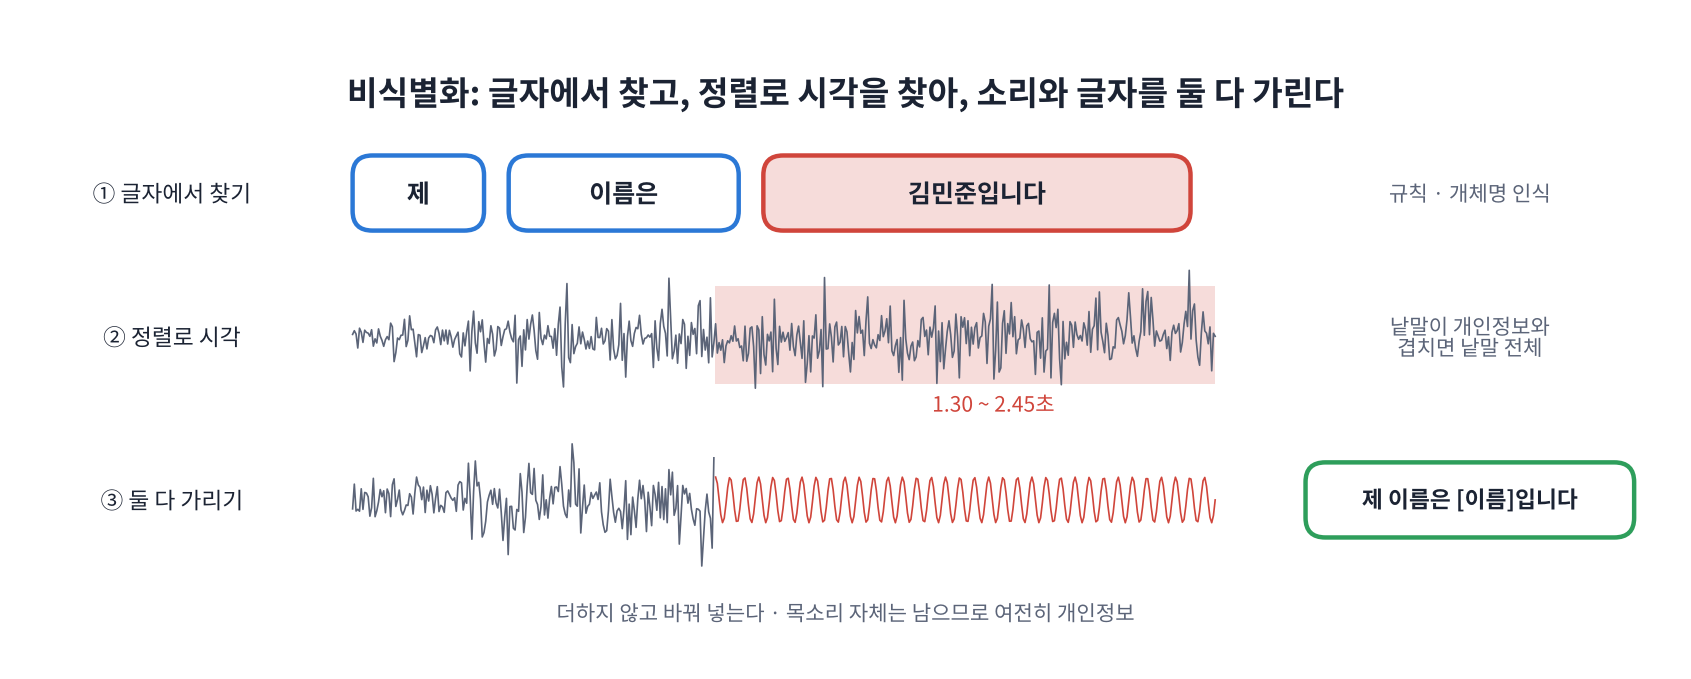

👣 **한 단계씩**
1. **찾기**: 글자에서 개인정보가 든 곳을 찾음 (규칙 또는 개체명 인식 모델)
2. **글자 가리기**: 그 자리를 `[이름]` · `[전화번호]` 같은 표시로 바꿈
3. **시각 찾기**: 2교시의 강제 정렬로 그 낱말이 **몇 초부터 몇 초까지**인지 찾음
4. **소리 가리기**: 그 구간을 비프음(또는 조용함)으로 **바꿔 넣음**. 앞뒤로 조금 여유를 둠

| 가리는 방법 | 소리 | 글자 | 학습에 미치는 영향 |
|---|---|---|---|
| 비프음 | 구간을 1 kHz 소리로 바꿈 | `[이름]` | 모델이 비프음을 표시로 배움. 가장 흔함 |
| 조용함 | 구간을 0으로 | `[이름]` | 문장이 끊겨 들림 |
| 바꿔 넣기 | 다른 가짜 이름을 TTS로 합성해 넣음 | 가짜 이름 | 자연스럽지만 만들기 어렵고 이음매가 남음 |

> 💬 **쉽게 말하면**: 방송에서 이름이 나올 때 '삐' 소리를 넣고 자막을 ○○○로 바꾸는 것과 같습니다. 소리와 자막을 **둘 다** 바꿔야 합니다.

> ⚠️ 비프음으로 가려도 **목소리 자체**는 남습니다. 목소리로 사람을 알아볼 수 있으므로(D35) 비식별화한 녹음도 여전히 개인정보로 다룹니다. 가리는 것은 **위험을 줄이는** 것이지 없애는 것이 아닙니다.

> 🎬 **애니메이션 D39-7:** [비식별화](https://imguru-mooc.github.io/AI_Voice/day39/animation.html#deid) — 글자에서 찾은 구간이 정렬을 거쳐 소리의 비프 구간이 되기까지

> ## 🎤 4교시 · Part 4-1 비식별화 (6분) — 슬라이드 p.15 · 🎬 D39-7
>
> 🎯 개인정보는 **소리와 글자 양쪽**에서 지운다. 글자에서 찾고 → 정렬로 시각을 찾아 → 소리를 바꿔 넣는다.
>
> 🗣️ "환자가 '제 이름은 김민준입니다, 전화번호는 공일공 …'이라고 말했습니다. 글자에서 이름을 `[이름]`으로 바꾸면 끝일까요? 녹음을 틀면 이름이 그대로 들립니다."
>
> 🖥️ [D39-7](https://imguru-mooc.github.io/AI_Voice/day39/animation.html#deid) → ▶ 시연 보기. 네 단계, '더하기'의 문제, '꼴이 다른 문장'을 놓치는 것까지.
>
> ⚠️ 표 아래의 경고를 읽습니다. 가려도 **목소리 자체**가 남으므로 여전히 개인정보입니다.

In [ ]:
# ✍️ 직접 작성 4 (4교시): 소리의 한 구간을 비프음으로 바꾸는 함수
# y는 16 kHz 소리(numpy 배열), start · end는 가릴 구간(초)입니다.
# y를 복사한 뒤, int(start × SR)번째부터 int(end × SR)번째 앞까지를 amp × sin(2π × freq × t)로 바꿔 돌려주세요. (t = 표본 번호 ÷ SR, 3 ~ 4줄)
def beep(y, start, end, freq=1000.0, amp=0.1):
    ...                                                  # ← 이 줄을 지우고 작성하세요

_y = np.linspace(-0.5, 0.5, SR).astype(np.float32); _y0 = _y.copy()
def _check():
    out = beep(_y, 0.25, 0.75)
    if out is None or out is Ellipsis: return None
    spec = np.abs(np.fft.rfft(out[4000:12000]))
    return [len(out), float(np.abs(out[:4000] - _y0[:4000]).sum() + np.abs(out[12000:] - _y0[12000:]).sum()), float(np.abs(out[4000:12000]).max()),
            float(np.argmax(spec) * SR / 8000), float(np.abs(_y - _y0).sum())]
W4_OK = practice(_check, [SR, 0.0, 0.1, 1000.0, 0.0], tol=1e-3)
if W4_OK: play(beep(SESSIONS[0]["wav"][:6 * SR], 1.0, 2.0), SR, "앞 6초 가운데 1 ~ 2초를 비프음으로")

<details>
<summary><b>💡 힌트 보기 (클릭)</b></summary>

1. 원본을 바꾸지 않도록 먼저 복사합니다: `out = y.copy()`. 구간의 표본 번호는 `a, b = int(start * SR), int(end * SR)`.
2. 구간의 시간축: `t = np.arange(b - a) / SR`. 비프음: `amp * np.sin(2 * np.pi * freq * t)`.
3. `out[a:b] = amp * np.sin(2 * np.pi * freq * t)` 다음에 `return out`.

</details>

<details>
<summary><b>🔑 정답 보기 (클릭)</b></summary>

```python
def beep(y, start, end, freq=1000.0, amp=0.1):
    out = y.copy()
    a, b = int(start * SR), int(end * SR)
    t = np.arange(b - a) / SR
    out[a:b] = amp * np.sin(2 * np.pi * freq * t)
    return out
```

**해설**: 채점은 다섯 가지를 봅니다. 길이가 그대로인지, **구간 밖은 한 표본도 바뀌지 않았는지**, 구간 안의 최댓값이 `amp`(0.1)인지, 구간 안의 주파수가 1000 Hz인지, 그리고 **원본 `y`가 바뀌지 않았는지**입니다. 가장 중요한 것은 `out[a:b] = ...`로 **바꿔 넣는** 것입니다. `out[a:b] += ...`로 **더하면** 원래 목소리 위에 비프음이 얹힐 뿐이어서, 비프음을 빼거나 걸러 내면 이름이 다시 들립니다. 비식별화에서 흔한 실수입니다(채점에서는 최댓값이 0.1을 넘어 틀립니다). `y.copy()`를 빼먹으면 원본 녹음이 망가져 다시 처리할 수 없습니다. 원본은 접근을 제한한 곳에 따로 두고, 데이터셋에는 가린 사본만 넣습니다.

</details>

> ## 🎤 ✍️ 직접 작성 4 · 비프음 (7분)
>
> 🎯 구간의 표본을 비프음으로 **바꿔 넣는다**(더하지 않는다). 원본은 건드리지 않는다.
>
> 🆘
> 1. `out = y.copy()`, `a, b = int(start * SR), int(end * SR)`
> 2. `t = np.arange(b - a) / SR`
> 3. `out[a:b] = amp * np.sin(2 * np.pi * freq * t)`; `return out`
>
> ⚠️ 흔한 오답: `out[a:b] += ...` → 최댓값이 0.1을 넘어 ❌. **이 오답이 오늘 가장 중요한 토론거리**입니다. "더한 비프음은 뺄 수 있습니다. 1 kHz만 걸러 내면 이름이 다시 들립니다." `y.copy()`를 빼먹으면 마지막 시험(원본이 바뀌었나)에서 틀립니다.
>
> 🎧 정답 뒤 1 ~ 2초가 비프음으로 바뀐 소리를 듣습니다.

In [ ]:
# ⭐ 핵심 코드: 비식별화 — 글자에서 찾아 가리고, 정렬로 시각을 찾아 소리도 가리기
PII = [("이름", r"(?<=이름은 )[가-힣]{2,4}(?= ?(?:입니다|이에요|예요|이고))"),                                        # ✏️ 찾는 규칙 (실무에서는 개체명 인식 모델과 함께)
       ("전화번호", r"[공영일이삼사오육칠팔구]{3,4}(?:[ -]?[공영일이삼사오육칠팔구]{3,4}){1,2}|\d{2,4}[- ]?\d{3,4}[- ]?\d{4}")]
BEEP_PAD = 0.05                                          # ✏️ 가릴 구간의 앞뒤 여유(초)

def find_pii(text):                                      # → [(종류, 시작 글자 위치, 끝 글자 위치), ...]
    return sorted((kind, m.start(), m.end()) for kind, pat in PII for m in re.finditer(pat, text))

def mask_text(text):
    for kind, a, b in reversed(find_pii(text)): text = text[:a] + f"[{kind}]" + text[b:]                   # ⭐ 뒤에서부터 바꿔야 앞의 위치가 밀리지 않음
    return text

def mask_audio(y, text):                                 # → (가린 소리, 가린 구간들)
    spans, pos, out = find_pii(text), 0, y.copy(); cut = []
    for w, s, e in align_words(y, text):                                                                  # ⭐ 낱말마다의 시각 (2교시의 강제 정렬)
        a = text.index(w, pos); b = a + len(w); pos = b
        if any(a < pb and pa < b for _, pa, pb in spans): cut.append((max(0.0, s - BEEP_PAD), min(len(y) / SR, e + BEEP_PAD)))   # ⭐ 낱말이 개인정보와 겹치면 가림
    for s, e in cut:
        i, j = int(s * SR), int(e * SR); out[i:j] = 0.1 * np.sin(2 * np.pi * 1000 * np.arange(j - i) / SR)   # ⭐ 더하지 않고 바꿔 넣음
    return out, cut

for text in ["제 이름은 김민준입니다.", "전화번호는 공일공 일이삼사 오육칠팔입니다.", "010-1234-5678로 연락 주세요.", "일이 많아서 금요일에 갈게요."]:
    print(f"{text}  →  {mask_text(text)}")
demo = [x for x in SEGS.itertuples() if find_pii(TRUTH.get(x.id, ""))][:2]
for r in demo:
    y2, cut = mask_audio(r.wav, TRUTH[r.id])
    print(f"\n{r.id}: {mask_text(TRUTH[r.id])} · 가린 구간 {[(round(s, 2), round(e, 2)) for s, e in cut]}")
    play(r.wav, SR, "가리기 전"); play(y2, SR, "가린 뒤"); print("   가린 소리를 받아쓰면:", stt(y2))
r = demo[0] if demo else SEGS.iloc[0]; y2, cut = mask_audio(r.wav, TRUTH.get(r.id, "제 이름은 김민준입니다."))
verify(mask_text("제 이름은 김민준입니다.") == "제 이름은 [이름]입니다." and "공일공" not in mask_text("전화번호는 공일공 일이삼사 오육칠팔입니다.") and mask_text("일이 많아서 금요일에 갈게요.") == "일이 많아서 금요일에 갈게요."
       and len(cut) >= 1 and len(y2) == len(r.wav) and not np.allclose(y2, r.wav), "이름 · 전화번호는 글자에서 가려지고, 개인정보가 없는 문장은 그대로 · 소리는 길이가 같고 구간만 바뀜")

> ## 🎤 ⭐ 비식별화 실행 (8분) — 슬라이드 p.16
>
> 🔍
> - `reversed(find_pii(text))` — "뒤에서부터 바꿉니다. 앞에서부터 바꾸면 글자 수가 달라져 뒤의 위치가 밀립니다."
> - `for w, s, e in align_words(y, text)` — "2교시의 정렬이 여기서 쓰입니다."
> - `if any(a < pb and pa < b ...)` — "낱말이 개인정보와 조금이라도 겹치면 낱말 전체."
> - `out[i:j] = ...` — "바꿔 넣기."
>
> ✅ 네 예문: 이름 · 전화번호(한글 숫자) · 전화번호(아라비아 숫자)는 가려지고 "일이 많아서 …"는 그대로. 이어서 두 조각의 가리기 전 · 후를 듣습니다.
>
> 🎧 "가린 뒤 소리에서 이름이 들리나요?" 그리고 "가린 소리를 받아쓰면" 줄을 봅니다. 이름이 남아 있으면 정렬이 어긋난 것입니다(특히 어림 정렬일 때).
>
> ❓ "'저 김민준인데요'는 가려질까요?" → 안 된다. 규칙에 없는 꼴. `mask_text("저 김민준인데요")`를 실행해 보입니다. → 규칙 + 개체명 인식 + 사람 검수.
>
> 💡 "일이 많아서"가 가려지지 않게 한 것은 숫자 글자 묶음이 둘 이상 이어져야 한다는 조건입니다. 반대로 "이삼일 사오일 걸려요" 같은 문장은 잘못 가려질 수 있습니다. 놓침과 오탐 사이의 선택입니다.

<details>
<summary><b>🔍 핵심 줄 해설 보기 (클릭)</b></summary>

```python
for kind, a, b in reversed(find_pii(text)): text = text[:a] + f"[{kind}]" + text[b:]
for w, s, e in align_words(y, text):
if any(a < pb and pa < b for _, pa, pb in spans): cut.append(...)
out[i:j] = 0.1 * np.sin(...)
```

**해설**: **찾기**는 여기서 정규식 두 개입니다. 이름은 "이름은 ○○○입니다" 꼴에서, 전화번호는 한글로 읽은 숫자(`공일공 일이삼사 …`)나 아라비아 숫자가 이어진 꼴에서 찾습니다. 네 번째 예 "**일이** 많아서"가 가려지지 않는 것은 숫자 글자가 3자 이상 이어진 묶음이 둘 이상 있어야 하기 때문입니다. 규칙은 이렇게 **놓치는 것(미탐)과 잘못 가리는 것(오탐)** 사이에서 정합니다. 개인정보는 놓치는 쪽이 더 위험하므로 넉넉하게 잡고, 실무에서는 개체명 인식(NER) 모델과 규칙을 함께 쓴 뒤 **표본을 사람이 들어 봅니다.** "저 김민준인데요"처럼 꼴이 다른 문장은 이 규칙으로 못 잡습니다. **글자 가리기**는 뒤에서부터 바꿉니다. 앞에서부터 바꾸면 글자 수가 달라져 뒤쪽 위치가 밀립니다. **소리 가리기**는 낱말 단위입니다. 낱말의 글자 범위가 개인정보의 범위와 조금이라도 겹치면 그 낱말 전체를 가립니다(그래서 '김민준입니다'의 '입니다'까지 가려집니다. 모자란 것보다 넘치는 편이 안전합니다). 가린 소리를 받아쓴 결과에 이름이 남아 있는지 보세요. 남아 있다면 정렬이 어긋났거나 여유(`BEEP_PAD`)가 모자란 것입니다. 2교시에서 CTC 모델을 못 올려 어림 정렬을 쓰고 있다면 구간이 어긋날 수 있습니다.

</details>

### 4-2. 나누기: 같은 사람이 학습용과 평가용에 함께 들어가지 않게

데이터를 학습용(train) · 검증용(valid) · 평가용(test)으로 나눌 때 **조각을 무작위로** 나누면, 같은 사람의 목소리가 학습용과 평가용에 함께 들어갑니다. 모델은 그 사람의 목소리를 이미 들어 봤으므로 평가 점수가 실제보다 **좋게** 나옵니다. 이것을 **누출**(leakage)이라고 합니다.

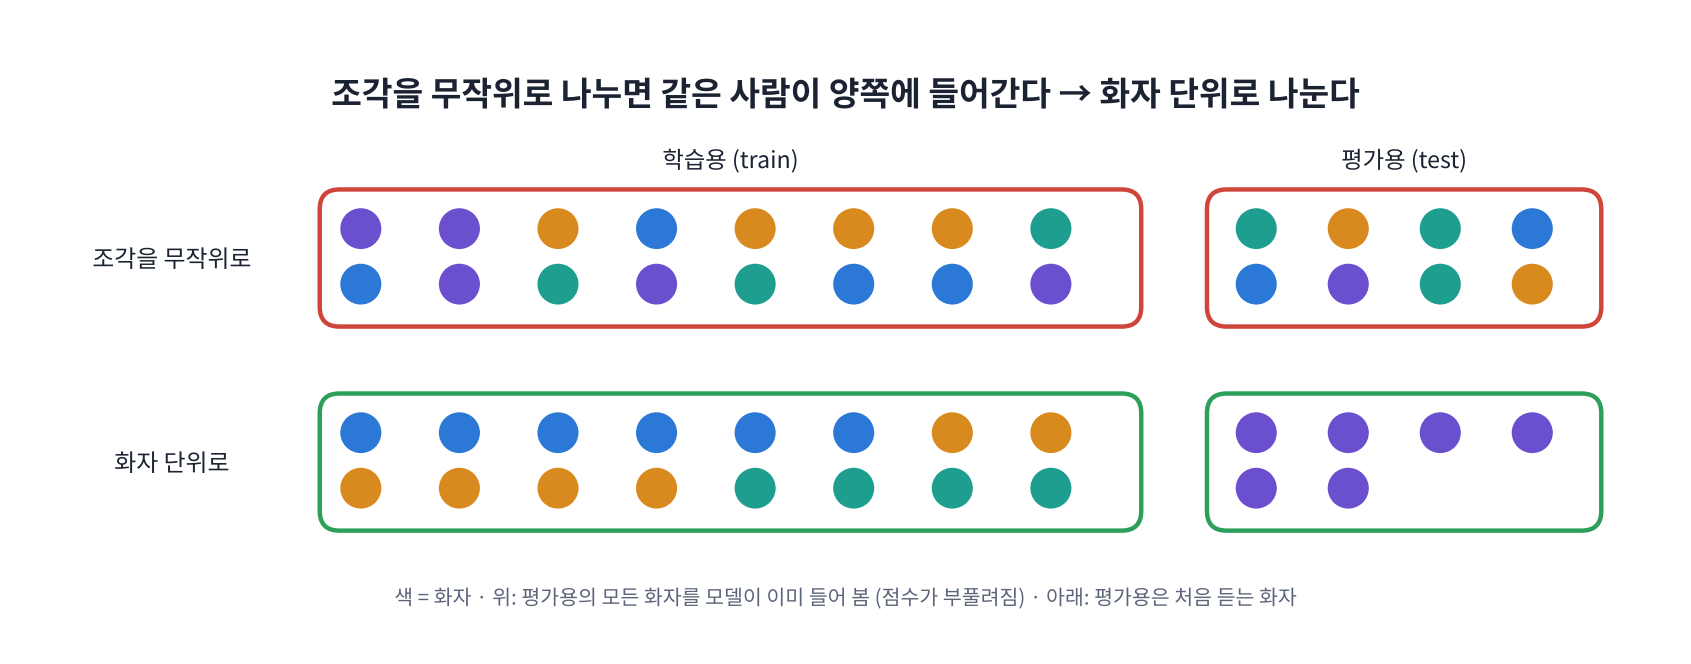

| 규칙 | 까닭 |
|---|---|
| **화자 단위로** 나눈다 | 평가는 '처음 듣는 사람'의 목소리로 해야 실제 성능 |
| 같은 녹음에서 나온 조각 · **증강본**은 원본과 같은 쪽에 | 증강본은 원본과 같은 사람 · 같은 문장 |
| **합성 음성 · 증강본은 학습용에만** | 평가는 실제 조건의 실제 녹음으로 |
| 평가용은 한 번 정하면 **바꾸지 않는다** | 모델끼리 비교하려면 같은 문제로 채점 |

> 💬 **쉽게 말하면**: 모의고사 문제가 실제 시험에 그대로 나오면 점수는 높지만 실력은 알 수 없습니다.

> 🎬 **애니메이션 D39-8:** [화자 단위 나누기](https://imguru-mooc.github.io/AI_Voice/day39/animation.html#split) — 무작위로 나눌 때와 화자 단위로 나눌 때 평가 점수가 어떻게 달라 보이는지

> ## 🎤 Part 4-2 · 화자 단위 나누기 (5분) — 슬라이드 p.17 · 🎬 D39-8
>
> 🎯 조각이 아니라 **화자**를 나눈다. 같은 사람이 양쪽에 있으면 점수가 부풀려진다.
>
> 🖥️ [D39-8](https://imguru-mooc.github.io/AI_Voice/day39/animation.html#split) → ▶ 시연 보기. 무작위일 때 두 막대가 벌어지고, 화자 단위일 때 같아지는 것.
>
> 🗣️ "모의고사 문제가 실제 시험에 그대로 나오면 점수는 높습니다. 실력은 모릅니다. D48 경진대회에서 숨은 평가셋으로 채점할 때 이 차이를 직접 겪게 됩니다."
>
> ❓ "3교시 질문: 속도 증강본의 화자는 원래 화자와 같게 적나요?" → 같게. 다르게 적으면 증강본이 평가용으로 갈 수 있다.

In [ ]:
# ⭐ 핵심 코드: 라벨 확정 → 비식별화 → 화자 단위로 나누기 → Hugging Face datasets 형식으로 저장
MIN_CONF, MAX_SCRIPT_CER, SEED = 0.8, 0.3, 0             # ✏️ 가짜 라벨의 확신 문턱 · 대본과 받아쓰기가 이보다 다르면 버림 · 나누기 씨앗
DS_DIR = "hanbit_speech_mini"
shutil.rmtree(DS_DIR, ignore_errors=True); os.makedirs(f"{DS_DIR}/audio")
import datasets; datasets.disable_progress_bars()

items = []                                               # ① 실제 녹음: 품질 통과 + 라벨 확정
for r in SEGS[SEGS.ok].itertuples():
    if r.id in TRUTH and cer(TRUTH[r.id], r.text) <= MAX_SCRIPT_CER: label, how = TRUTH[r.id], "script"    # 대본이 있고 받아쓰기와 맞음 → 대본을 씀
    elif r.id not in TRUTH and r.conf >= MIN_CONF: label, how = r.text, "pseudo"                           # 대본이 없음 → 확신이 높은 가짜 라벨
    else: continue
    wav, _ = mask_audio(r.wav, label)                                                                      # ⭐ 소리 가리기
    items.append(dict(id=r.id, speaker=r.speaker, text=mask_text(label), source="real", label_from=how, snr=float(r.snr), wav=wav))   # ⭐ 글자 가리기
for r in SYN[SYN.ok].itertuples():                       # ② 합성 음성 (역검증 통과)
    items.append(dict(id=r.id, speaker=r.speaker, text=r.text, source="synth", label_from="script", snr=60.0, wav=r.wav))

def split_speakers(speakers, seed=SEED):                 # 화자 목록 → {화자: "train" | "valid" | "test"}
    sp = sorted(speakers); random.Random(seed).shuffle(sp)
    n_test = 1 if len(sp) >= 2 else 0; n_valid = 1 if len(sp) >= 3 else 0
    return {s: ("test" if i < n_test else "valid" if i < n_test + n_valid else "train") for i, s in enumerate(sp)}   # ⭐ 화자 한 명은 한쪽에만

real_speakers = {x["speaker"] for x in items if x["source"] == "real"}
WHERE = split_speakers(real_speakers)
for x in items: x["split"] = WHERE[x["speaker"]] if x["source"] == "real" else "train"                     # ⭐ 합성 음성은 학습용에만
rng = np.random.default_rng(SEED); aug_names = [k for k in AUG if k != "원본"]
for x in [x for x in items if x["split"] == "train" and x["source"] == "real"]:                            # ③ 증강본: 학습용의 실제 녹음마다 하나, 원본과 같은 화자 · 같은 쪽
    name = aug_names[int(rng.integers(len(aug_names)))]
    items.append({**x, "id": x["id"] + "_aug", "source": "aug:" + name, "wav": AUG[name](x["wav"])})

rows = []
for x in items:
    path = f'{DS_DIR}/audio/{x["id"]}.wav'; sf.write(path, x["wav"], SR)
    rows.append({k: x[k] for k in ["id", "speaker", "text", "source", "label_from", "snr", "split"]} | {"audio": path, "sec": round(len(x["wav"]) / SR, 2)})
META = pd.DataFrame(rows)
ds = DatasetDict({name: Dataset.from_list(META[META.split == name].drop(columns="split").to_dict("records")).cast_column("audio", HFAudio(sampling_rate=SR))   # ⭐ audio 열을 '소리'로 선언
                  for name in ["train", "valid", "test"] if (META.split == name).any()})
ds.save_to_disk(f"{DS_DIR}/hf"); META.to_json(f"{DS_DIR}/metadata.jsonl", orient="records", lines=True, force_ascii=False)
print(ds); display(META.groupby(["split", "source"]).agg(조각=("id", "size"), 초=("sec", "sum"), 화자=("speaker", "nunique")).round(1))

back = load_from_disk(f"{DS_DIR}/hf"); first = back["train"].cast_column("audio", HFAudio(decode=False))[0]   # 다시 읽어 확인 (디코더 없이 바이트로)
y0, sr0 = sf.read(io.BytesIO(first["audio"]["bytes"]) if first["audio"].get("bytes") else first["audio"]["path"])
print(f'다시 읽은 첫 조각: {first["id"]} · {first["text"]} · {len(y0) / sr0:.2f}초 · {sr0} Hz')
by = {name: set(META[META.split == name].speaker) for name in ["train", "valid", "test"]}
rand = META[META.source == "real"].assign(split=lambda d: np.where(np.random.default_rng(1).permutation(len(d)) < 0.8 * len(d), "train", "test"))   # 비교: 조각을 무작위로 8 : 2로 나눴다면
print("무작위로 나눴다면 학습용과 평가용에 모두 들어가는 화자:", sorted(set(rand[rand.split == "train"].speaker) & set(rand[rand.split == "test"].speaker)))
verify(not (by["train"] & by["test"]) and not (by["train"] & by["valid"]) and not (by["valid"] & by["test"]) and set(META[META.source != "real"].split) <= {"train"}
       and not META.text.str.contains("|".join(NAMES.values())).any() and "S04" not in set(META.speaker),
       "화자가 두 쪽에 겹치지 않음 · 합성 · 증강은 학습용에만 · 글자에 이름이 남지 않음 · 동의하지 않은 S04는 없음")

> ## 🎤 ⭐ 라벨 확정 → 가리기 → 나누기 → 저장 (10분) — 슬라이드 p.18
>
> 🔍 이 셀은 하루 전체를 묶습니다. 위에서부터 다섯 덩어리로 읽습니다.
> 1. **라벨 확정**: 대본이 있고 받아쓰기와 30% 안으로 맞으면 대본, 대본이 없으면 확신 0.8 이상의 가짜 라벨
> 2. **가리기**: `mask_audio` · `mask_text`
> 3. **나누기**: `split_speakers` — 화자 이름을 섞어 test · valid · train. 합성은 train에만
> 4. **증강**: train의 실제 녹음마다 하나, `{**x, ...}`로 화자와 split을 물려받음
> 5. **저장**: wav 파일 → `Dataset.from_list` → `cast_column("audio", HFAudio(...))` → `save_to_disk`
>
> ✅ `DatasetDict`에 train · valid · test가 보이고, 표에 split × source별 조각 수가 나옵니다. "다시 읽은 첫 조각" 줄이 나오면 저장이 된 것입니다. "무작위로 나눴다면 …" 줄에는 화자 이름이 여럿 나옵니다.
>
> ⚠️ 실제 녹음 화자가 둘뿐이면(S03이 SNR로 다 빠지고 다른 화자도 빠진 경우) valid가 없을 수 있습니다. 정상입니다.
>
> 🗣️ "`push_to_hub`는 쓰지 않습니다. 공개 동의가 False입니다. 코드 한 줄이 동의 범위를 넘습니다."
>
> 💡 `metadata.jsonl`을 열어 한 줄을 보여 줍니다. 한 줄 = 조각 하나. 다른 도구들이 읽는 흔한 형식입니다.

<details>
<summary><b>🔍 핵심 줄 해설 보기 (클릭)</b></summary>

```python
wav, _ = mask_audio(r.wav, label);  text=mask_text(label)
return {s: ("test" if i < n_test else "valid" if … else "train") for i, s in enumerate(sp)}
x["split"] = WHERE[x["speaker"]] if x["source"] == "real" else "train"
Dataset.from_list(...).cast_column("audio", HFAudio(sampling_rate=SR))
```

**해설**: **라벨 확정**: 대본대로 읽은 녹음은 대본을 정답으로 쓰되, 가짜 라벨(받아쓰기)과 30% 넘게 다르면 "대본과 다르게 읽었거나 잘못 잘린 조각"으로 보고 버립니다. 가짜 라벨이 여기서는 **검사 도구**로 쓰입니다. 대본이 없는 조각은 확신이 높은 가짜 라벨만 씁니다. `label_from` 열에 어느 쪽인지 남겨 둡니다. **나누기**: `split_speakers`는 **조각이 아니라 화자 이름**을 섞어 나눕니다. 그래서 한 화자의 조각은 모두 같은 쪽으로 갑니다. 화자가 서너 명뿐이라 평가용이 한 명이지만, 실제로는 화자 수십 ~ 수백 명을 성별 · 나이대가 고르게 섞이도록 나눕니다. 출력의 "무작위로 나눴다면 …" 줄을 보세요. 조각을 무작위로 나누면 거의 모든 화자가 양쪽에 들어갑니다. **증강본**은 `{**x, …}`로 원본의 `speaker`와 `split`을 그대로 물려받습니다(3교시 '생각해 보기' 3번의 답: 속도를 바꿔 다른 사람처럼 들려도 **같은 화자**로 적습니다). **저장**: `cast_column("audio", HFAudio(...))`는 "이 열의 글자는 파일 경로가 아니라 소리"라고 알려 주는 것입니다(D11). `save_to_disk`로 저장한 폴더는 D12 · D13의 파인튜닝 코드와 내일 D40에서 그대로 읽을 수 있습니다. `metadata.jsonl`은 한 줄에 조각 하나씩 적은 표로, 다른 도구(Kaldi · NeMo · ESPnet)가 읽는 흔한 형식입니다. 허브에 올리는 `push_to_hub`는 **쓰지 않습니다.** 오늘 데이터는 가상이지만, 실제 녹음이라면 공개 동의(`publish`)가 없는 데이터를 올리는 것이 됩니다.

</details>

### 4-3. 데이터 카드: 이 데이터가 무엇인지 적어 두기

데이터셋 폴더만 넘겨받은 사람은 **누가, 어떻게, 무슨 허락으로 만든 데이터인지, 어디에 쓰면 안 되는지** 알 수 없습니다. 데이터 카드(README)는 그것을 적는 문서입니다. D35 · D36의 모델 카드와 짝을 이룹니다.

| 항목 | 적을 내용 |
|---|---|
| 목적과 쓰면 안 되는 곳 | 무엇을 위해 만들었나 · 화자 식별이나 감정 평가에 쓰지 않기 |
| 구성 | 조각 수 · 시간 · 화자 수 · 나눈 방법 |
| 수집과 동의 | 녹음 방법 · 동의 범위 · 기한 · **철회 절차** |
| 처리 | VAD · 거른 기준 · 라벨 방식 · 증강 · 비식별화 |
| 치우침과 한계 | 성별 · 나이대 · 기기 · 장소 · 잡음의 분포, 알려진 문제 |

In [ ]:
# 🗂️ 데이터 카드 만들기 + 동의 철회 처리
def data_card(meta):
    tab = meta.groupby("split").agg(조각=("id", "size"), 분=("sec", lambda s: round(s.sum() / 60, 2)), 화자=("speaker", "nunique"))
    src = meta.source.str.split(":").str[0].value_counts().to_dict(); real = meta[meta.source == "real"]
    dev = {s["speaker"]: f'{s["device"]} · {s["place"]}' for s in SESSIONS}
    lines = ["# 한빛치과 예약 통화 미니 데이터셋 (수업용 · 가상)", "",
             "## 목적", "- 치과 예약 통화의 한국어 음성 인식(ASR) 파인튜닝 연습", "- **쓰면 안 되는 곳**: 화자 식별 · 감정 평가 · 음성 복제, 공개 배포", "",
             "## 구성", "| 나눔 | 조각 | 분 | 화자 |", "|---|---|---|---|"] + [f"| {k} | {r.조각} | {r.분} | {r.화자} |" for k, r in tab.iterrows()] + [
             f"- 출처별 조각 수: {src} (real = 실제 녹음, synth = TTS 합성, aug = 증강)", "- 나눈 방법: **화자 단위**. 합성 · 증강은 train에만", "",
             "## 수집과 동의", f"- 화자 {len(SESSIONS)}명이 대본 {len(SCRIPT)}문장을 읽음 · 16 kHz · 수집일 {SESSIONS[0]['date']}",
             f"- 학습 동의 {sum(c['train'] for c in CONSENT.values())}명 · 공개 동의 {sum(c['publish'] for c in CONSENT.values())}명 · 동의하지 않은 화자의 녹음은 넣지 않음",
             f"- 사용 기한: {sorted({c['until'] for c in CONSENT.values() if c['until']})} · 기한이 지나면 삭제", "- **철회 절차**: 화자 가명으로 요청 → `remove_speaker()`로 조각과 파일 삭제 → 이 데이터로 학습한 모델 목록 확인", "",
             "## 처리", f"- 분할: 에너지 VAD (바닥 + {VAD_UP} dB, 틈 {VAD_GAP}초)", f"- 거르기: 길이 {MIN_SEC} ~ {MAX_SEC}초 · SNR {MIN_SNR} dB 이상",
             f"- 라벨: 대본(받아쓰기와 CER {MAX_SCRIPT_CER:.0%} 이하일 때) 또는 가짜 라벨({ASR_NAME}, 확신 {MIN_CONF} 이상)",
             f"- 증강(train만): {', '.join(k for k in AUG if k != '원본')}", f"- 합성: Edge TTS · 역검증 CER {MAX_RT_CER:.0%} 이하만",
             "- 비식별화: 이름 · 전화번호를 글자에서는 `[이름]` · `[전화번호]`로, 소리에서는 1 kHz 비프음으로 바꿈 (규칙 기반 · 사람 검수 전)", "",
             "## 치우침과 한계", f"- 실제 녹음 화자: {sorted(set(real.speaker))} · 기기와 장소: { {k: v for k, v in dev.items() if k in set(real.speaker)} }",
             f"- 실제 녹음의 SNR: {real.snr.min():.0f} ~ {real.snr.max():.0f} dB → 시끄러운 통화는 거의 없음",
             "- 화자가 매우 적고 모두 대본을 읽은 말투 → 자유 발화 · 사투리 · 어르신 · 어린이 목소리가 없음", "- 목소리 자체는 가려지지 않으므로 개인정보로 다룰 것"]
    return "\n".join(lines)

CARD = data_card(META); open(f"{DS_DIR}/README.md", "w", encoding="utf-8").write(CARD); display(Markdown(CARD))

def remove_speaker(meta, speaker):                       # 동의 철회: 그 화자의 조각과 파일을 모두 지움
    gone = meta[meta.speaker == speaker]
    for p in gone.audio:
        if os.path.exists(p): os.remove(p)
    return meta[meta.speaker != speaker].reset_index(drop=True), len(gone)

who = next((s for s, w in WHERE.items() if w == "train"), sorted(WHERE)[0])
print(f"\n(연습) {who}이(가) 동의를 철회하면 {int((META.speaker == who).sum())}개 조각(증강본 포함)을 지워야 합니다. 실제로 지우려면: META, n = remove_speaker(META, \"{who}\") 다음에 데이터셋을 다시 저장")

> ## 🎤 데이터 카드 (5분) — 슬라이드 p.19
>
> 🎯 데이터셋 폴더만으로는 **무엇인지** 알 수 없다. 카드에 목적 · 동의 · 처리 · 한계를 적는다.
>
> 🗣️ "이 폴더를 석 달 뒤의 나, 또는 옆 팀이 받았다고 합시다. 무엇이 궁금할까요?" → 학생 답을 받고 카드의 항목과 맞춰 봅니다.
>
> ✅ 출력된 카드를 위에서부터 읽습니다. '쓰면 안 되는 곳'과 '치우침과 한계'에 시간을 씁니다. "SNR 범위를 보세요. 시끄러운 통화가 없다고 **스스로 적었습니다.**"
>
> ❓ "한계를 솔직히 적으면 손해 아닌가요?" → 적지 않으면 쓰는 사람이 모르고 잘못 쓴다. D36 · D35의 모델 카드와 같은 이유.
>
> 💡 마지막 줄의 `remove_speaker`는 실행하지 않고 읽기만 합니다. 철회 요청이 오면 조각 · 증강본 · 파일을 지우고 데이터셋을 다시 저장합니다.

In [ ]:
# 🧾 오늘의 성적표: 녹음이 데이터셋이 되기까지 몇 개가 남았나
n_seg = len(SEGS); n_ok = int(SEGS.ok.sum()); n_real = int((META.source == "real").sum())
SUMMARY = pd.DataFrame([
    {"단계": "① 수집", "한 일": f"화자 {len(SESSIONS)}명 · 세션 {sum(len(s['wav']) for s in SESSIONS) / SR / 60:.1f}분", "남은 것": f"{len(SESSIONS)}개 세션"},
    {"단계": "② VAD 분할", "한 일": f"바닥 + {VAD_UP} dB · 틈 {VAD_GAP}초", "남은 것": f"{n_seg}개 조각"},
    {"단계": "③ 품질 · 동의 거르기", "한 일": str(SEGS[~SEGS.ok].why.value_counts().to_dict()), "남은 것": f"{n_ok}개"},
    {"단계": "④ 라벨 확정", "한 일": f"대본 {int(((META.source == 'real') & (META.label_from == 'script')).sum())}개 · 가짜 라벨 {int(((META.source == 'real') & (META.label_from == 'pseudo')).sum())}개 · 버림 {n_ok - n_real}개", "남은 것": f"{n_real}개"},
    {"단계": "⑤ 합성 · 증강", "한 일": f"합성 {int((META.source == 'synth').sum())}개 · 증강 {int(META.source.str.startswith('aug').sum())}개", "남은 것": f"{len(META)}개"},
    {"단계": "⑥ 비식별화", "한 일": f"가림 표시가 든 조각 {int(META.text.str.contains('[', regex=False).sum())}개", "남은 것": f"{len(META)}개"},
    {"단계": "⑦ 나누기 · 저장", "한 일": " · ".join(f"{k} {len(v)}" for k, v in ds.items()), "남은 것": f"{META.sec.sum() / 60:.1f}분 · {DS_DIR}/"}])
display(SUMMARY)
print("만든 파일:", sorted(os.listdir(DS_DIR)), "· 소리 파일", len(os.listdir(f"{DS_DIR}/audio")), "개")

> ## 🎤 성적표 (2분)
>
> ✅ ① ~ ⑦ 단계의 '남은 것' 열을 위에서 아래로 읽습니다. "세션 5개 → 조각 50개 안팎 → 30개 안팎 → … → 55개 안팎." 숫자는 반마다 다릅니다.
>
> 🗣️ "처음의 3분 남짓한 녹음에서 쓸 수 있는 실제 녹음은 절반 남짓입니다. 실제 프로젝트에서도 수집한 양의 절반이 남으면 잘한 것입니다."

## 4교시 마무리: 한계와 규칙

| 단계 | 흔한 실패 | 대비 |
|---|---|---|
| 수집 | 동의 범위를 넘어 씀, 철회를 반영하지 못함 | 조각마다 화자 가명 · 동의 기록 연결, 철회 절차 문서화 |
| VAD 분할 | 문장 중간에서 잘림, 두 문장이 붙음 | 틈 · 여유 조절, 학습된 VAD(D4), 잘린 조각은 정렬 점수로 거름 |
| 품질 거르기 | 깨끗한 것만 남겨 실제 조건에 약함 | 학습용 기준과 평가용 기준을 따로, 잡음 분포 기록 |
| 가짜 라벨 | 자신 있게 틀린 라벨(이름 · 숫자 · 용어) | 확신 + 사람 표본 검수, 용어 문장은 반드시 확인 |
| 증강 | 사람도 못 알아듣는 수준, 평가용에 섞임 | SNR 범위 제한, 학습용에만 |
| 합성 데이터 | 합성 목소리에만 맞춰짐 | 실제 녹음과 섞는 비율 정하기, 카드에 표시 |
| 비식별화 | 꼴이 다른 문장을 놓침, 소리만 또는 글자만 가림 | 규칙 + NER + 사람 검수, **소리와 글자 둘 다** |
| 나누기 | 화자 누출로 점수가 부풀려짐 | 화자 단위, 평가용 고정 |

> ⚖️ 이 수업은 연습입니다. 실제 서비스에서 녹음을 모아 학습에 쓰려면 개인정보 보호 법령 · 회사 규정 · 고지와 동의 문구를 **담당 부서와 함께** 확인해야 합니다(D43에서 다시 다룹니다).

### 📝 워크시트
수업을 모두 마쳤습니다. [worksheet.html](https://imguru-mooc.github.io/AI_Voice/day39/worksheet.html)에서 **25문항**을 풉니다. 채점 후 **오답 정리 복사** → 노션에 붙여 넣기. (데이터셋 · 녹음 파일은 노션에 올리지 않습니다.)

> 🎬 **애니메이션 D39-9:** [정리 퀴즈](https://imguru-mooc.github.io/AI_Voice/day39/animation.html#recap)

> ## 🎤 4교시 마무리 · 워크시트 (10분) — 슬라이드 p.19 · 🎬 D39-9
>
> 🗣️ 한계 표를 한 줄씩 읽지 말고 **"오늘 우리 파이프라인에서 가장 불안한 단계는 어디인가요?"** 를 묻습니다. 예상 답: 비식별화(규칙이 놓침), 가짜 라벨(자신 있게 틀림).
>
> 🖥️ [D39-9](https://imguru-mooc.github.io/AI_Voice/day39/animation.html#recap) 정리 퀴즈 여섯 문제를 반 전체가 손을 들어 답합니다.
>
> 📝 [워크시트](https://imguru-mooc.github.io/AI_Voice/day39/worksheet.html) 25문항. 교시별 문항: 1교시 1 ~ 6 · 2교시 7 ~ 13 · 3교시 14 ~ 19 · 4교시 20 ~ 25. 19번(직접 조작)은 확신 문턱 슬라이더로, 답은 0.56(0.57도 정답)입니다. 코드 직접 쓰기 답: 3번 `percentile` · 9번 `exp` · 14번 `sqrt` · 22번 `HFAudio`(`Audio`도 정답).
>
> ⚠️ 노션에는 오답 정리 글만 붙입니다. 데이터셋 폴더 · 녹음 파일은 올리지 않습니다.

## Part 5. 정리

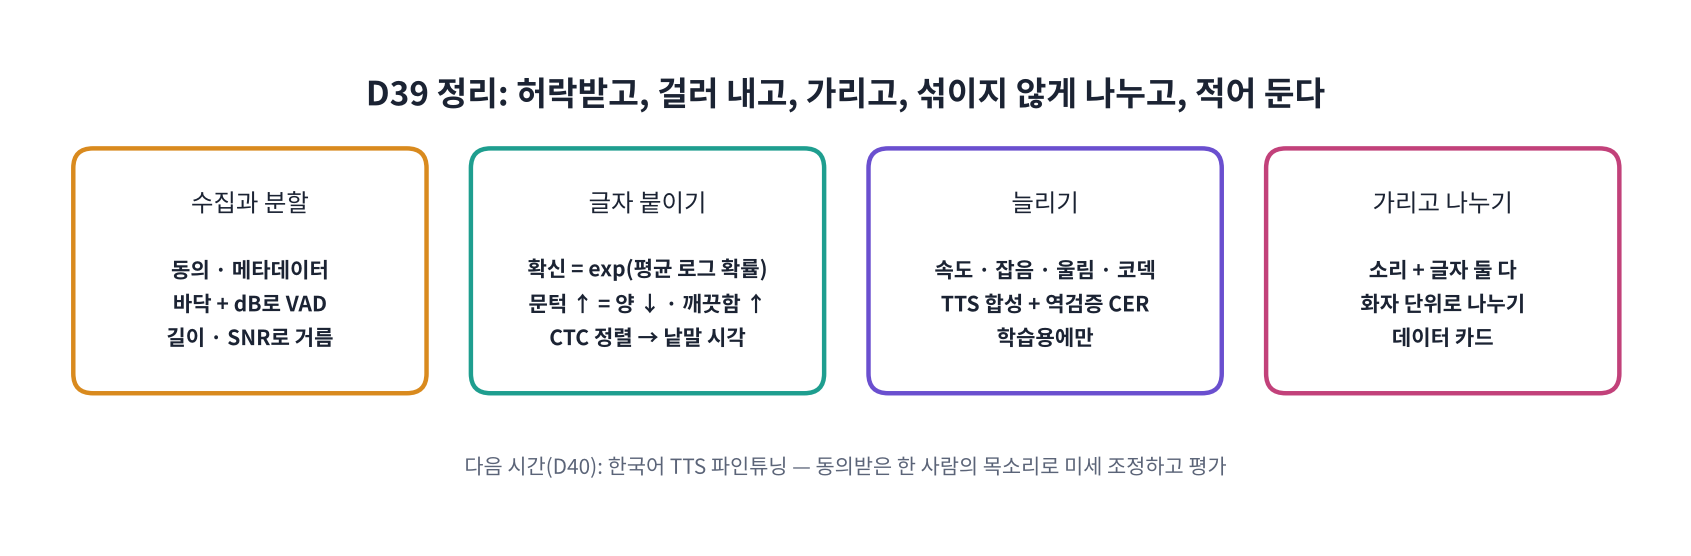

| 오늘 만든 것 | 핵심 |
|---|---|
| `vad_split` · `quality` | 녹음의 바닥보다 몇 dB 큰 곳이 말. 길이 · SNR · **동의**로 거름 |
| `pseudo_label` · `confidence` | 확신 = exp(평균 로그 확률). 문턱을 올리면 양이 줄고 라벨이 깨끗해짐 |
| `ctc_align` · `align_words` | 대본을 따라가는 가장 좋은 길 → 낱말마다의 시각 |
| `aug_*` · `mix_at_snr` | 속도 · 잡음 · 울림 · 코덱. **학습용에만** |
| `SYN` (합성 + 역검증) | 없는 문장을 TTS로 만들고 받아쓰기로 확인 |
| `mask_text` · `mask_audio` · `beep` | 글자와 소리를 **둘 다** 가림. 더하지 않고 바꿔 넣음 |
| `split_speakers` · `ds` · 데이터 카드 | 화자 단위로 나누고, 무엇인지 적어 둠 |

**오늘의 한 문장**: 좋은 모델은 좋은 데이터에서 나오고, 좋은 데이터는 **허락받고, 걸러 내고, 가리고, 섞이지 않게 나누고, 무엇인지 적어 둔** 데이터입니다.

**다음 시간 (D40) 한국어 TTS 파인튜닝**: 오늘의 방법으로 준비한 **동의받은 한 사람의 목소리**로 TTS를 미세 조정하고, 역검증 CER · 화자 유사도(D35)로 평가합니다.

> 🧹 마치기 전에: 실제 녹음으로 실습했다면 `shutil.rmtree(DS_DIR)`로 데이터셋 폴더를 지우고, 런타임 연결을 끊습니다.

> ## 🎤 Part 5 · 정리 (3분) — 슬라이드 p.20
>
> 🗣️ 칠판의 세 문장을 다시 읽습니다. "허락받지 않은 녹음은 쓰지 않는다. 문턱은 쓰임새가 정한다. 둘 다 가리고, 화자로 나누고, 적어 둔다."
>
> ➡️ "내일 D40은 오늘의 방법으로 준비한 **한 사람의 목소리**로 TTS를 파인튜닝합니다. 오늘은 ASR용 데이터였지만 TTS용 데이터는 기준이 더 엄격합니다. 잡음이 조금만 있어도 합성 음성에 그대로 배어 나옵니다."
>
> 📝 과제(선택): 내 목소리로 문장 다섯 개를 녹음해(직접 동의 기록을 쓰고) 오늘의 파이프라인에 넣어 보기. 조각 수 · SNR · 확신을 표로 정리해 노션에(글과 표만, 녹음은 올리지 않기).
>
> 🧹 실제 녹음으로 실습한 학생은 `shutil.rmtree(DS_DIR)`를 실행하게 합니다.